# Human PBMCs

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2024-11-29
> - Modified: 2026-01-03
---

> - [20k Human PBMCs Multiplex Sample (Donors 1-4)](https://www.10xgenomics.com/cn/datasets/20k_Human_Donor1-4_PBMC_3p_gem-x_multiplex)
> - Organism: Homo sapiens
> - Tissue: PBMCs
> - 10X Universal 3' v4 scRNA-seq
> - 2024-11-19
---

# Experimental Design

> - GEM-X Universal 3' Gene Expression v4 4-plex On-chip Multiplexing (CG000768)
> - Chromium X Series
> - Illumina NovaSeq 6000
> - Cell Ranger v9.0.0
>     - multi

| Sample | Tissue | Full name | Gender | Age | Disease status |
| - | - | - | - | - | - |
| Donors 1~4 | PBMCs | Peripheral blood mononuclear cells | Male | 18~35 | Healthy |
| Donors 1~4 | PBMCs | Peripheral blood mononuclear cells | Female | 36-50 | Healthy |

---

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(Seurat))
suppressPackageStartupMessages(library(cowplot))

── Attaching core tidyverse packages ──────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.2
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


# 1. Data Import

In [2]:
data_dir <- "~/data1/single_cell_dataset/dataset_10xGenomics/Hs_PBMCs_3Pv4_20k"

In [3]:
dir.create(file.path(data_dir, "result"), 
           recursive = TRUE, showWarnings = FALSE)
dir.create(file.path(data_dir, "visualization"), 
           recursive = TRUE, showWarnings = FALSE)

In [4]:
samples <- file.path(data_dir, "matrix") |>
    list.files(full.names = FALSE, recursive = TRUE) |>
    grep("filtered_feature_bc_matrix.h5", x = _, value = TRUE)

names(samples) <- file.path(data_dir, "matrix") |>
    list.dirs(full.names = FALSE, recursive = FALSE)

paste(names(samples), samples, sep = ": ") |> cat(sep = "\n")

Donor1: Donor1/filtered_feature_bc_matrix.h5
Donor2: Donor2/filtered_feature_bc_matrix.h5
Donor3: Donor3/filtered_feature_bc_matrix.h5
Donor4: Donor4/filtered_feature_bc_matrix.h5


In [5]:
load_mtx_to_seurat <- function(path, sample, name = sample) {
    file.path(path, sample) |> 
        Read10X_h5() |>
        CreateSeuratObject(project = name)
}

In [6]:
scrna_list <- mapply(
    FUN = load_mtx_to_seurat,
    sample = samples,
    name = names(samples),
    MoreArgs = list(path = file.path(data_dir, "matrix")), 
    SIMPLIFY = FALSE)

In [7]:
scrna_list

$Donor1
An object of class Seurat 
38606 features across 4629 samples within 1 assay 
Active assay: RNA (38606 features, 0 variable features)
 1 layer present: counts

$Donor2
An object of class Seurat 
38606 features across 5958 samples within 1 assay 
Active assay: RNA (38606 features, 0 variable features)
 1 layer present: counts

$Donor3
An object of class Seurat 
38606 features across 4531 samples within 1 assay 
Active assay: RNA (38606 features, 0 variable features)
 1 layer present: counts

$Donor4
An object of class Seurat 
38606 features across 5048 samples within 1 assay 
Active assay: RNA (38606 features, 0 variable features)
 1 layer present: counts


# 2. Quality Control

In [8]:
cell_stats <- function(obj_list) {
    cells_per_object <- vapply(
        obj_list, function(x) length(Cells(x)), 
        FUN.VALUE = integer(1))
    total_cells <- sum(cells_per_object)
    
    c(cells_per_object, Total = total_cells)
}

In [9]:
scrna_list |> cell_stats() |> print()

Donor1 Donor2 Donor3 Donor4  Total 
  4629   5958   4531   5048  20166 


## 1). Filtering Genes

In [10]:
filter_low_detected_genes <- function(
    obj_list, min_cells = 3) {

    genes_list <- lapply(obj_list, function(obj){
        mat <- LayerData(obj, layer = "counts")
        gene_detect <- rowSums(mat > 0)
        names(gene_detect[gene_detect >= min_cells])
    })
    names(genes_list) <- names(obj_list)
    
    keep_genes <- Reduce(union, genes_list)
    
    message("Genes after filtering in each layer:")
    print(lengths(genes_list))
    message("Final intersected gene count: ", length(keep_genes))

    return(keep_genes)
}

In [11]:
keep_genes <- filter_low_detected_genes(
    scrna_list, min_cells = 3)

Genes after filtering in each layer:



Donor1 Donor2 Donor3 Donor4 
 25949  25501  23952  24839 


Final intersected gene count: 27812



In [12]:
scrna_list <- lapply(
    scrna_list, function(obj) 
        subset(obj, features = keep_genes))

## 2). Calculate Metrics

In [13]:
calculate_qc_metrics <- function(
    obj, species = c("human", "mouse")) {
    
    species <- match.arg(species)
    
    # Mitochondrial genes
    mt_pattern <- "(?i)^MT-"
    obj <- PercentageFeatureSet(
        obj, pattern = mt_pattern, col.name = "percent.mt")
    
    # Ribosomal genes
    rp_pattern <- "(?i)^(MRP|RP[LS])"
    obj <- PercentageFeatureSet(
        obj, pattern = rp_pattern, col.name = "percent.rp")
    
    # Hemoglobin genes
    hb_pattern <- switch(
        species,
        human = "^(HBA1|HBA2|HBAP1|HBB|HBBP1|HBD|HBE1|HBG1|HBG2|HBM|HBQ1|HBZ|HBZP1)",
        mouse = "^(Hb[ab]-|Hbq1[ab])"
    )
    obj <- PercentageFeatureSet(
        obj, pattern = hb_pattern, col.name = "percent.hb")
    
    return(obj)
}

In [14]:
scrna_list <- lapply(
    scrna_list, calculate_qc_metrics, species = "human")

## 3). Visualizate Metrics

In [15]:
source("R/run_seurat_pipeline.R")

In [16]:
sc.temp <- merge(x = scrna_list[[1]], y = scrna_list[-1],
                 add.cell.ids = names(scrna_list)) |>
    run_seurat_pipeline(ndim = 20)
sc.temp

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”


An object of class Seurat 
27812 features across 20166 samples within 1 assay 
Active assay: RNA (27812 features, 2000 variable features)
 9 layers present: counts.Donor1, counts.Donor2, counts.Donor3, counts.Donor4, data.Donor1, data.Donor2, data.Donor3, data.Donor4, scale.data
 3 dimensional reductions calculated: pca, umap, tsne

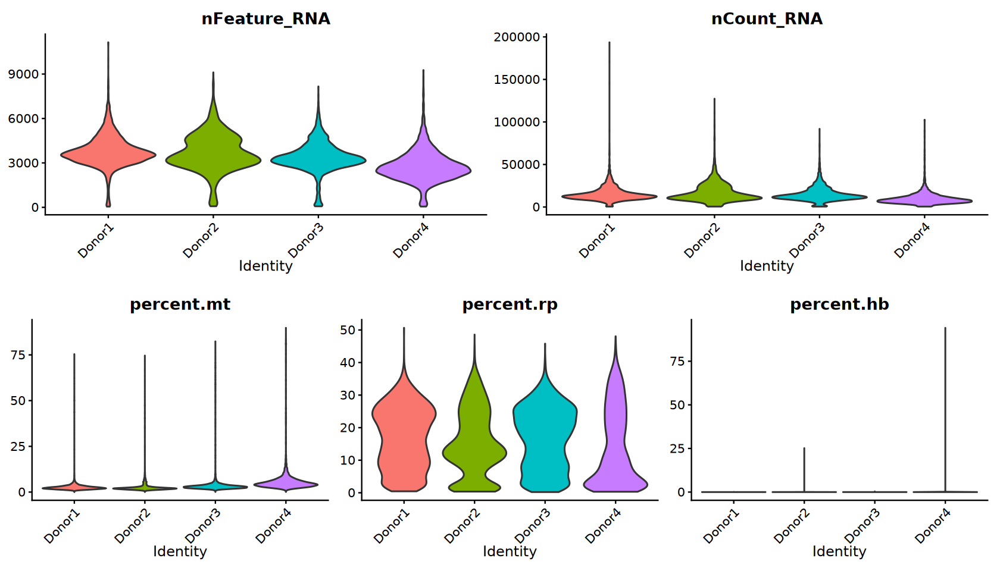

In [17]:
# Visualize QC metrics as a violin plot
p1 <- VlnPlot(
    sc.temp, layer = "counts", group.by = "orig.ident", 
    features = c("nFeature_RNA", "nCount_RNA"), 
    pt.size = 0, ncol = 2) & NoLegend()
p2 <- VlnPlot(
    sc.temp, layer = "counts", group.by = "orig.ident", 
    features = c("percent.mt", "percent.rp", "percent.hb"), 
    pt.size = 0, ncol = 3) & NoLegend()

options(repr.plot.width = 14, repr.plot.height = 8)
plot_grid(p1, p2, ncol = 1)

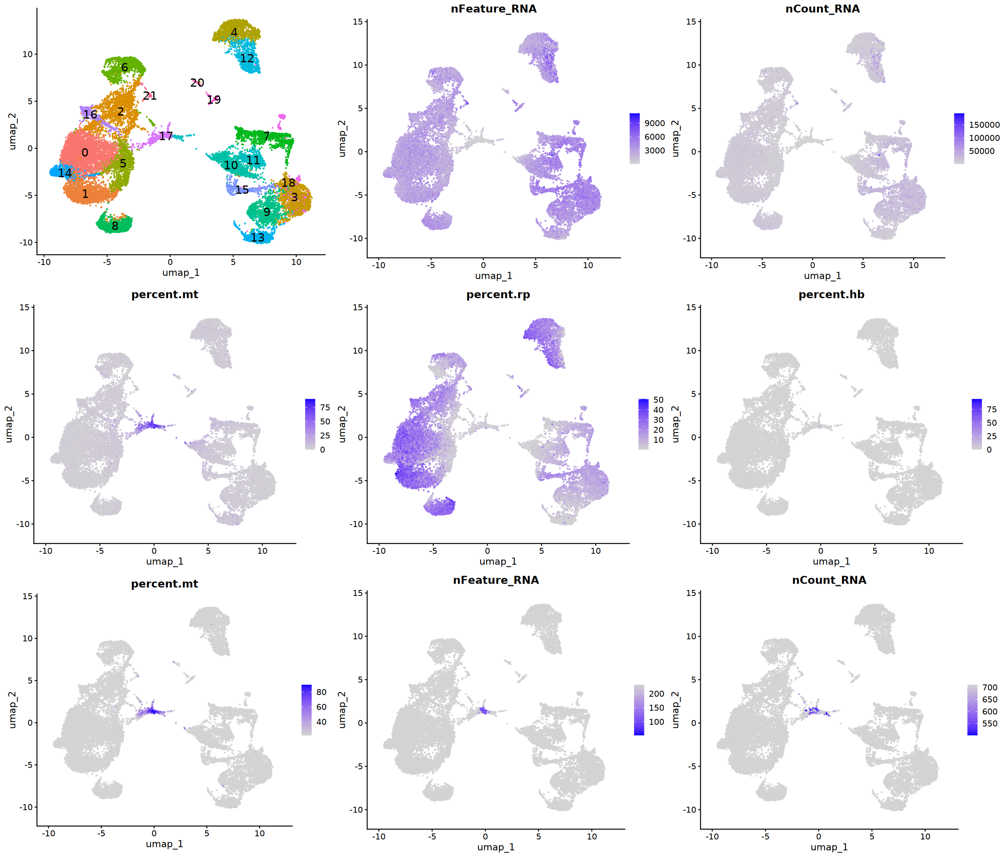

In [18]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", label = TRUE, 
    label.size = 6) & NoLegend()
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA", "percent.mt", 
                 "percent.rp", "percent.hb"))
p3 <- FeaturePlot(
    sc.temp, reduction = "umap", features = "percent.mt",
    min.cutoff = "q98", order = TRUE)
p4 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA"),
    max.cutoff = "q1", cols = c("blue", "lightgrey"))

options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(plotlist = c(p1, p2, p3, p4), ncol = 3)

In [19]:
source("R/calculate_mad_threshold.R")

In [20]:
cat(sprintf("Counts: Lower: %d\n", calculate_mad_threshold(
    sc.temp$nCount_RNA, nmads = 3, sides = "lower")))

cat(sprintf("Features: Lower: %d\n", calculate_mad_threshold(
    sc.temp$nFeature_RNA, nmads = 3, sides = "lower")))

cat(sprintf("Mitochondrial: Upper: %d\n", calculate_mad_threshold(
    sc.temp$percent.mt, nmads = 3, sides = "upper")))

Counts: Lower: 2538
Features: Lower: 1397
Mitochondrial: Upper: 13


## 4). Filtering Low-quality Cells

In [21]:
scrna_list <- lapply(
    scrna_list, subset, 
    subset = nFeature_RNA > 500 & 
        nCount_RNA > 1000 & 
        percent.mt < 15)

scrna_list |> cell_stats() |> print()

Donor1 Donor2 Donor3 Donor4  Total 
  4567   5802   4382   4856  19607 


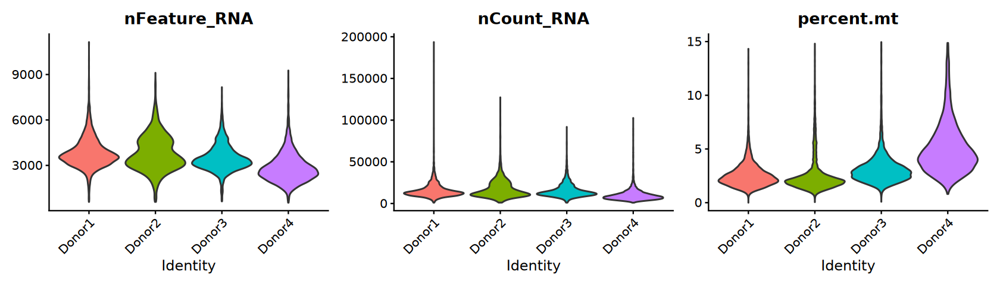

In [22]:
options(repr.plot.width = 14, repr.plot.height = 4)
merge(x = scrna_list[[1]], y = scrna_list[-1],
      add.cell.ids = names(scrna_list)) |>
VlnPlot(layer = "counts", group.by = "orig.ident", 
        features = c("nFeature_RNA", "nCount_RNA", "percent.mt"), 
        pt.size = 0, ncol = 3) & NoLegend()

## 5). Doublet Detection

### a). [DoubletFinder](https://github.com/chris-mcginnis-ucsf/DoubletFinder)

In [23]:
source("R/run_DoubletFinder.R")

In [24]:
scrna_list <- lapply(
    scrna_list, run_DoubletFinder, ndim = 20, 
    clusters = "seurat_clusters", 
    multiplet.rate = 0.008, seed = 123)

[1] "Creating 1522 artificial doublets..."
[1] "Classifying doublets.."


DoubletFinder completed: pN = 0.25, pK = 0.25, nExp_adj = 145



[1] "Creating 1934 artificial doublets..."
[1] "Classifying doublets.."


DoubletFinder completed: pN = 0.25, pK = 0.08, nExp_adj = 239



[1] "Creating 1461 artificial doublets..."
[1] "Classifying doublets.."


DoubletFinder completed: pN = 0.25, pK = 0.16, nExp_adj = 136



[1] "Creating 1619 artificial doublets..."
[1] "Classifying doublets.."


DoubletFinder completed: pN = 0.25, pK = 0.05, nExp_adj = 168



In [25]:
sapply(scrna_list, function(x) table(x$DoubletFinder.class))

,Donor1,Donor2,Donor3,Donor4
Singlet,4422,5563,4246,4688
Doublet,145,239,136,168


### b). [scDblFinder](https://github.com/plger/scDblFinder)

In [26]:
suppressPackageStartupMessages(library(scDblFinder))

In [27]:
run_scDblFinder <- function(
    obj, clusters = NULL, ndim = 10, seed = NULL) {
    
    if (!is.null(seed)) set.seed(seed)
    
    sce <- run_seurat_pipeline(obj, ndim = ndim) |>
        as.SingleCellExperiment()
    
    if (is.null(clusters)) {
        sce <- scDblFinder(sce, verbose = FALSE)
    } else {
        sce <- scDblFinder(
            sce, clusters = clusters, verbose = FALSE)
    }

    obj$scDblFinder.score <- colData(sce)$scDblFinder.score
    obj$scDblFinder.class <- colData(sce)$scDblFinder.class

    return(obj)
}

In [28]:
scrna_list <- lapply(
    scrna_list, run_scDblFinder, ndim = 20,
    clusters = "seurat_clusters", seed = 123)

In [29]:
sapply(scrna_list, function(x) table(x$scDblFinder.class))

,Donor1,Donor2,Donor3,Donor4
singlet,4229,5312,4081,4490
doublet,338,490,301,366


### Filtering Doublets

In [30]:
sc.comb <- merge(
    x = scrna_list[[1]], y = scrna_list[-1],
    add.cell.ids = names(scrna_list), 
    project = "PBMCs")
sc.comb

An object of class Seurat 
27812 features across 19607 samples within 1 assay 
Active assay: RNA (27812 features, 0 variable features)
 4 layers present: counts.Donor1, counts.Donor2, counts.Donor3, counts.Donor4

In [31]:
sc.temp <- run_seurat_pipeline(sc.comb, ndim = 20)

In [32]:
sc.temp$scDblFinder.class <- sc.temp$scDblFinder.class |>
    factor(levels = c("singlet", "doublet"))
sc.temp$DoubletFinder.class <- sc.temp$DoubletFinder.class |>
    factor(levels = c("Singlet", "Doublet"))

In [33]:
table(scDblFinder = sc.temp$scDblFinder.class, 
      DoubletFinder = sc.temp$DoubletFinder.class)

           DoubletFinder
scDblFinder Singlet Doublet
    singlet   17918     194
    doublet    1001     494

In [34]:
sc.temp$isDoublet <- apply(
    sc.temp@meta.data[, c(
        "scDblFinder.class", "DoubletFinder.class")],
    1, function(x) paste(x, collapse = "_")
    ) |> as.factor()

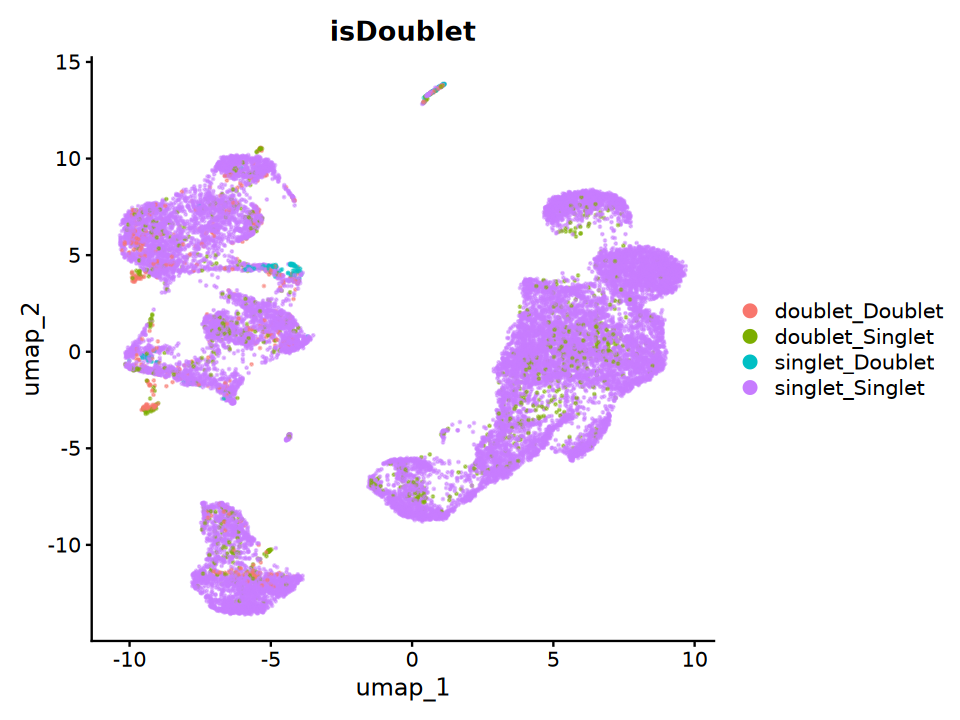

In [35]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(sc.temp, reduction = "umap", 
        group.by = "isDoublet", 
        pt.size = 0.1, alpha = 0.5)

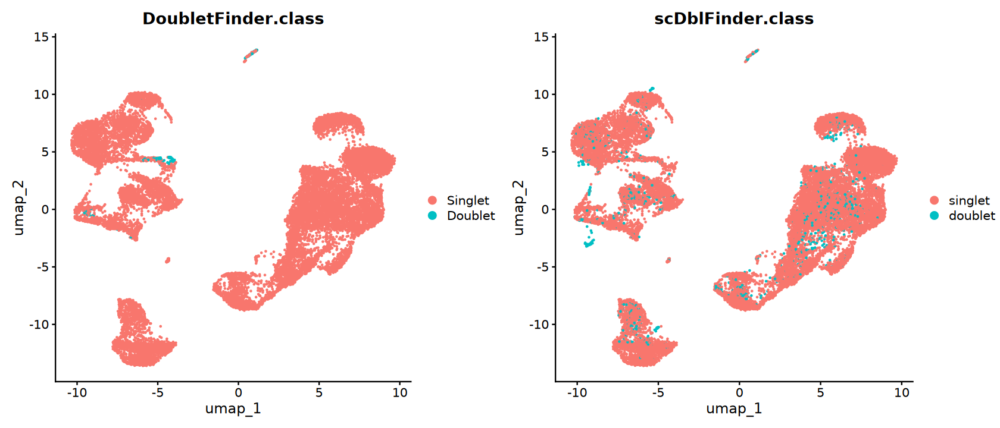

In [36]:
p1 <- DimPlot(
    subset(sc.temp, subset = scDblFinder.class == "singlet"),
    reduction = "umap", group.by = "DoubletFinder.class")
p2 <- DimPlot(
    subset(sc.temp, subset = DoubletFinder.class == "Singlet"), 
    reduction = "umap", group.by = "scDblFinder.class")

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

In [37]:
sc.temp <- subset(
    sc.temp,
    subset = scDblFinder.class == "singlet" |
        DoubletFinder.class == "Singlet")
sc.temp

An object of class Seurat 
27812 features across 19113 samples within 1 assay 
Active assay: RNA (27812 features, 2000 variable features)
 9 layers present: counts.Donor1, counts.Donor2, counts.Donor3, counts.Donor4, data.Donor1, data.Donor2, data.Donor3, data.Donor4, scale.data
 3 dimensional reductions calculated: pca, umap, tsne

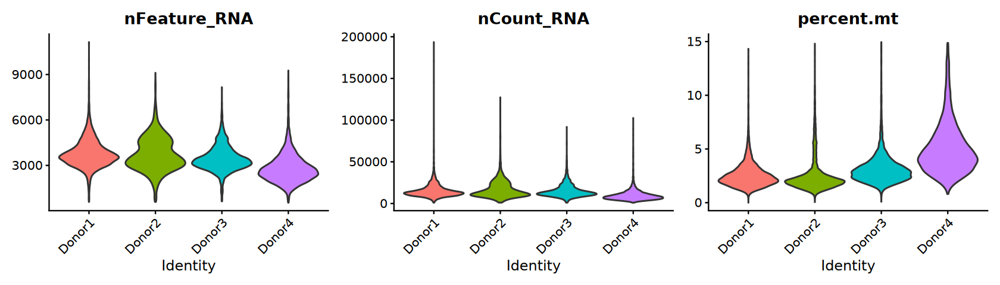

In [38]:
options(repr.plot.width = 14, repr.plot.height = 4)
VlnPlot(sc.temp, layer = "counts", group.by = "orig.ident", 
        features = c("nFeature_RNA", "nCount_RNA", "percent.mt"), 
        pt.size = 0, ncol = 3) & NoLegend()

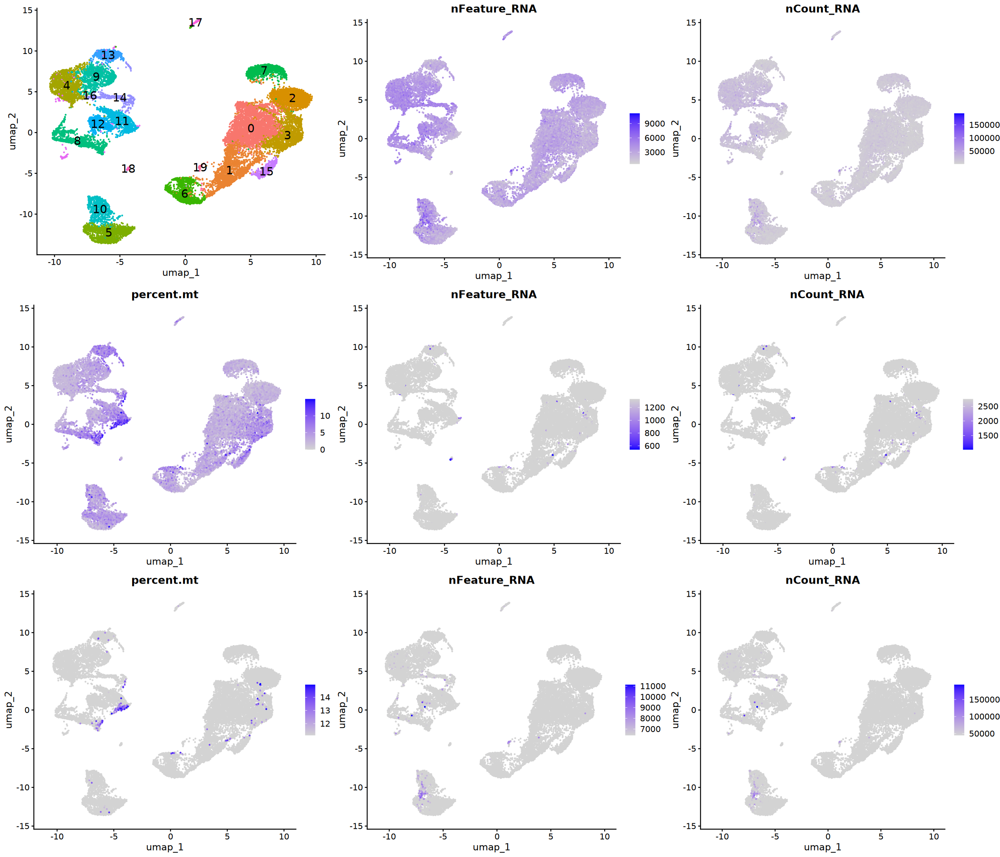

In [39]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", label = TRUE, 
    label.size = 6) & NoLegend()
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA", "percent.mt"))
p3 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA"),
    max.cutoff = "q1", cols = c("blue", "lightgrey"))
p4 <- FeaturePlot(
    sc.temp, reduction = "umap",
    features = c("percent.mt", "nFeature_RNA", "nCount_RNA"),
    min.cutoff = "q99", order = TRUE, combine = FALSE)

options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(plotlist = c(p1, p2, p3, p4), ncol = 3, byrow = TRUE)

In [40]:
summary(sc.temp@meta.data[, c("nFeature_RNA", "nCount_RNA", "percent.mt")])

  nFeature_RNA     nCount_RNA       percent.mt    
 Min.   :  541   Min.   :  1017   Min.   : 0.000  
 1st Qu.: 2786   1st Qu.:  8880   1st Qu.: 1.983  
 Median : 3331   Median : 12210   Median : 2.675  
 Mean   : 3448   Mean   : 14391   Mean   : 3.294  
 3rd Qu.: 4010   3rd Qu.: 17373   3rd Qu.: 3.967  
 Max.   :11140   Max.   :193589   Max.   :14.953  

In [41]:
cat(sprintf("Counts: Upper: %d\n", calculate_mad_threshold(
    sc.temp$nCount_RNA, nmads = 3, sides = "upper")))

cat(sprintf("Features: Upper: %d\n", calculate_mad_threshold(
    sc.temp$nFeature_RNA, nmads = 3, sides = "upper")))

Counts: Upper: 53664
Features: Upper: 7493


In [42]:
sc.comb <- sc.comb |> 
    subset(
        subset = scDblFinder.class == "singlet" |
            DoubletFinder.class == "Singlet") |>
    subset(
        subset = nCount_RNA < 50000 & 
            percent.mt < 15 & percent.hb < 1)
sc.comb

An object of class Seurat 
27812 features across 18990 samples within 1 assay 
Active assay: RNA (27812 features, 0 variable features)
 4 layers present: counts.Donor1, counts.Donor2, counts.Donor3, counts.Donor4

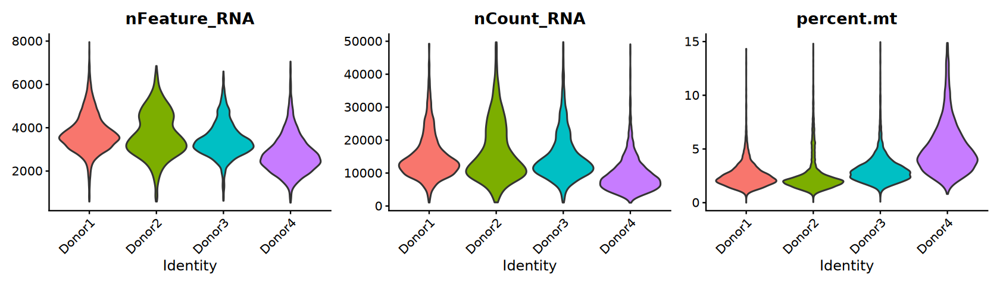

In [43]:
options(repr.plot.width = 14, repr.plot.height = 4)
VlnPlot(sc.comb, layer = "counts", group.by = "orig.ident", 
        features = c("nFeature_RNA", "nCount_RNA", "percent.mt"), 
        pt.size = 0, ncol = 3) & NoLegend()

## 6). Evaluating Noise

### a). Cell cycle effect

In [44]:
calculate_cell_cycle_score <- function(
    obj, species = c("human", "mouse")) {

    species <- match.arg(species)

    cc_s <- switch(
        species,
        "human" = cc.genes$s.genes,
        "mouse" = stringr::str_to_title(cc.genes$s.genes),
        tolower(cc.genes$s.genes))
    
    cc_g2m <- switch(
        species,
        "human" = cc.genes$g2m.genes,
        "mouse" = stringr::str_to_title(cc.genes$g2m.genes),
        tolower(cc.genes$g2m.genes))
    
    obj <- NormalizeData(obj, verbose = FALSE) |>
        CellCycleScoring(s.features = cc_s, g2m.features = cc_g2m, 
                         set.ident = FALSE)

    return(obj)
}

In [45]:
sc.comb <- calculate_cell_cycle_score(sc.comb, species = "human")

Warning message:
“The following features are not present in the object: MLF1IP, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM64A, HN1, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: MLF1IP, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM64A, HN1, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: MLF1IP, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM64A, HN1, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: MLF1IP, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM64A, HN1, not searching for symbol synonyms”


### b). Cell dissociation effect

In [46]:
dissociation_genes <- readLines(
    "~/data1/single_cell_dataset/reference_infomation/dissociation_genes.txt")

In [47]:
calculate_dissociation_score <- function(
    obj, species = c("human", "mouse")) {
    
    species <- match.arg(species)

    diss_genes <- switch(
        species,
        "human" = toupper(dissociation_genes),
        "mouse" = dissociation_genes,
        tolower(dissociation_genes)
    )
    
    obj <- NormalizeData(obj, verbose = FALSE) |>
        AddModuleScore(name = "Dissociation.Score", 
                       features = list(dissociationGenes = diss_genes))
    obj@meta.data <- obj@meta.data |> 
        dplyr::rename("Dis.Score" = "Dissociation.Score1")
    
    return(obj)
}

In [48]:
sc.comb <- calculate_dissociation_score(sc.comb, species = "human")

Warning message:
“The following features are not present in the object: H3F3B, ANKRD1, CYR61, FAM132B, MT1, DCN, MT2, CCRN4L, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: H3F3B, ANKRD1, CYR61, FAM132B, MT1, DCN, MT2, CCRN4L, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: H3F3B, ANKRD1, CYR61, FAM132B, MT1, DCN, MT2, CCRN4L, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: H3F3B, ANKRD1, CYR61, FAM132B, MT1, DCN, MT2, CCRN4L, not searching for symbol synonyms”


### c). Batch effect

In [49]:
sc.temp <- run_seurat_pipeline(sc.comb, ndim = 20)

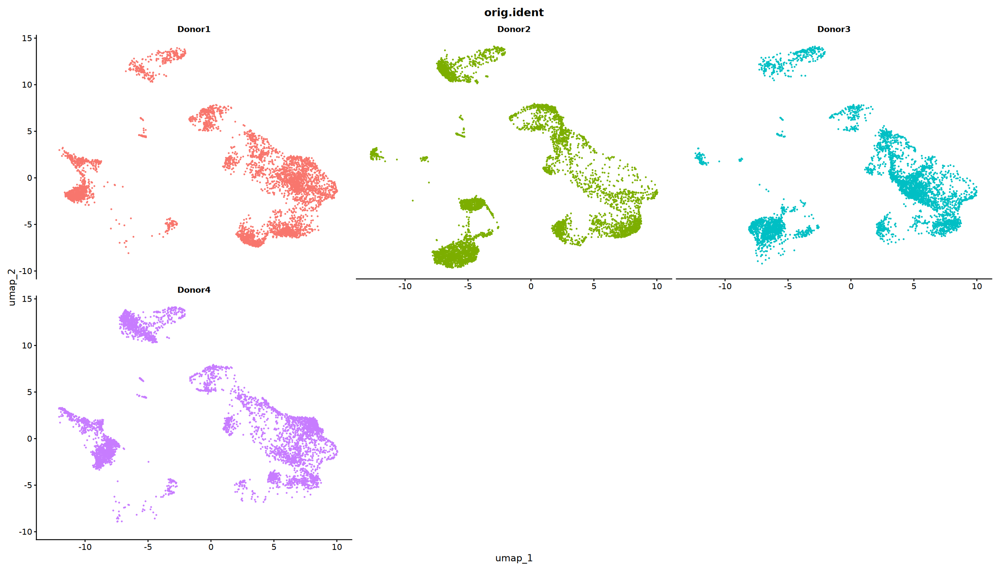

In [50]:
options(repr.plot.width = 12, repr.plot.height = 3)
DimPlot(sc.temp, reduction = "umap", group.by = "orig.ident", 
        split.by = "orig.ident", ncol = 4) & NoLegend()

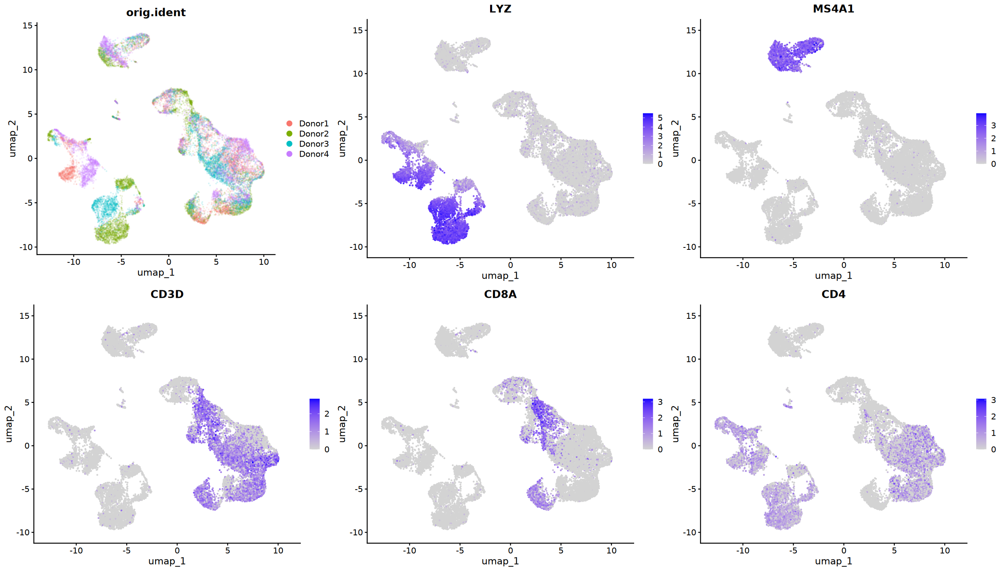

In [51]:
geneset <- c("LYZ", "MS4A1", "CD3D", "CD8A", "CD4")

p1 <- DimPlot(
    sc.temp, reduction = "umap", group.by = "orig.ident",
    pt.size = 0.1, alpha = 0.1, label = FALSE)
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", features = geneset,
    combine = FALSE)

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = c(p1, p2), ncol = 3)

# 3. Initial Assessment

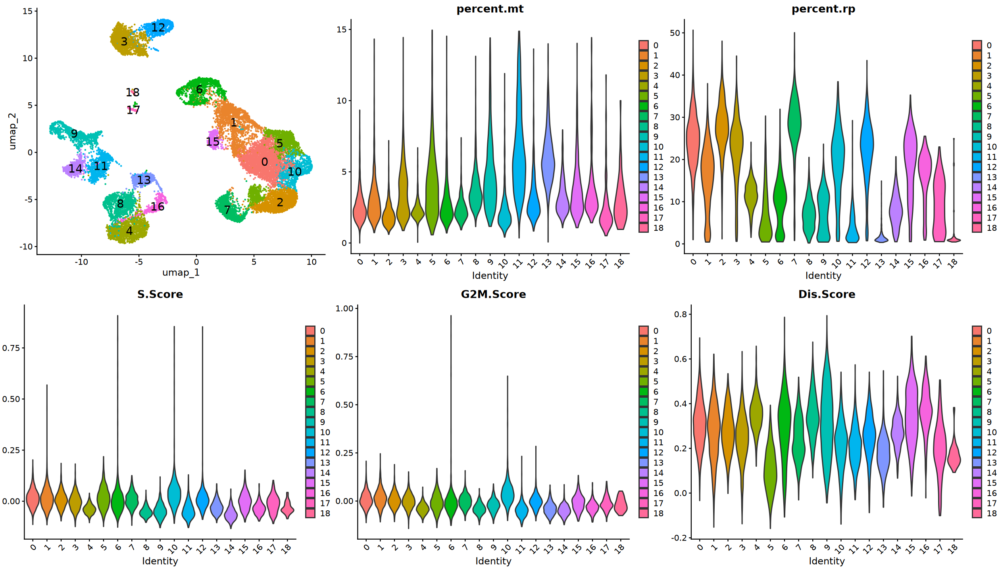

In [52]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", label = TRUE, 
    label.size = 6) & NoLegend()
p2 <- VlnPlot(
    sc.temp, features = c("percent.mt", "percent.rp"), 
    group.by = "seurat_clusters", pt.size = 0, combine = FALSE)
p3 <- VlnPlot(
    sc.temp, features = c("S.Score", "G2M.Score", "Dis.Score"), 
    group.by = "seurat_clusters", pt.size = 0, combine = FALSE)

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = c(p1, p2, p3), ncol = 3)

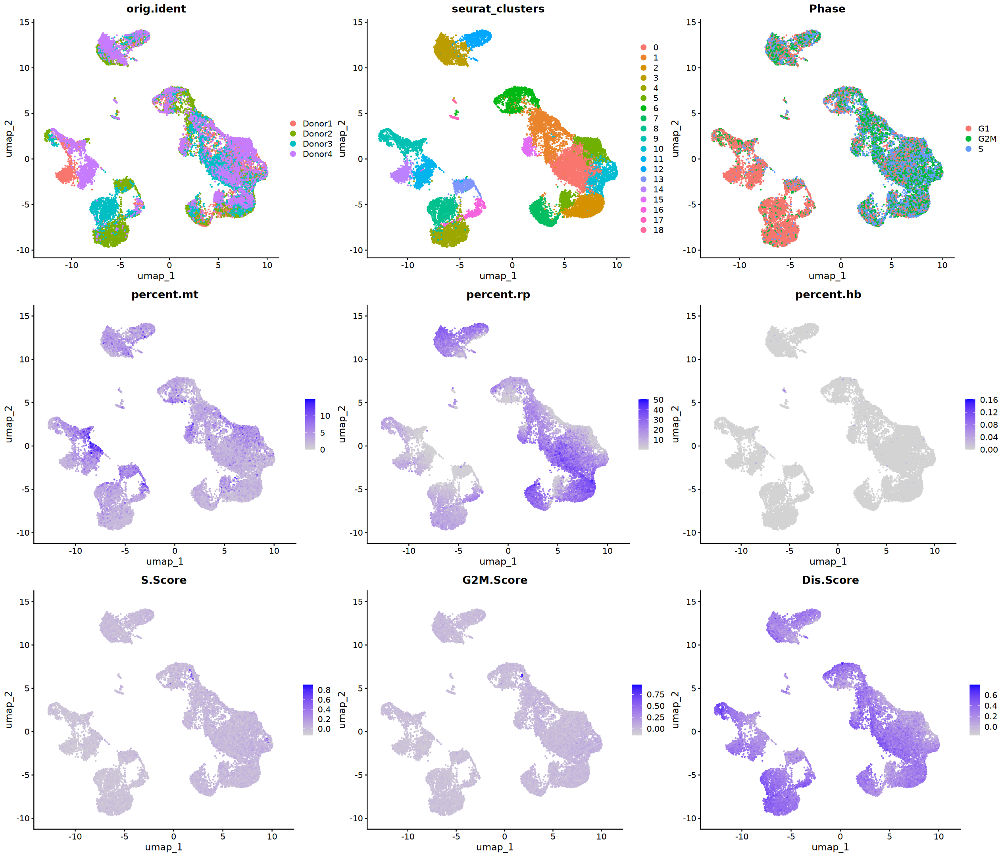

In [53]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", combine = FALSE,
    group.by = c("orig.ident", "seurat_clusters", "Phase"))
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("percent.mt", "percent.rp", "percent.hb", 
                 "S.Score", "G2M.Score", "Dis.Score"))

options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(plotlist = c(p1, p2), ncol = 3)

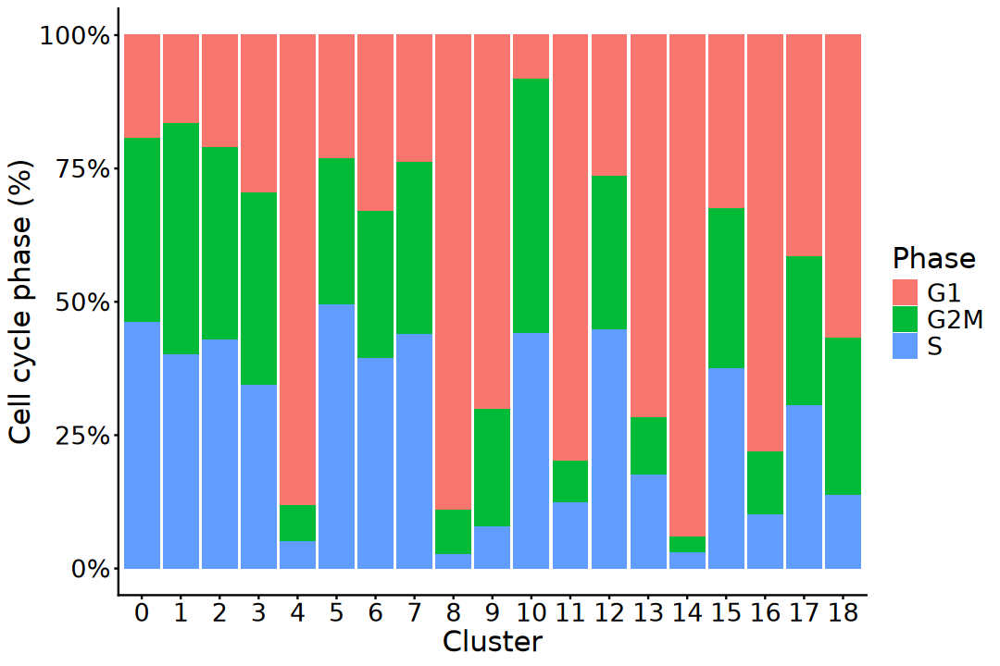

In [54]:
options(repr.plot.width = 9, repr.plot.height = 6)
table(sc.temp$seurat_clusters, sc.temp$Phase) |> 
    as.data.frame() |>
    ggplot(aes(x = Var1, y = Freq, fill = Var2)) +
        geom_bar(stat = "identity", position = "fill") +
        scale_y_continuous(labels = scales::percent_format()) +
        labs(x = "Cluster", y = "Cell cycle phase (%)", fill = "Phase") +
        theme_classic() + 
        theme(axis.title = element_text(size = 18),
              axis.text = element_text(size = 16),
              legend.title = element_text(size = 18),
              legend.text = element_text(size = 16))

In [55]:
pca <- Embeddings(sc.temp, "pca")[, 1:10]

vars <- c("nCount_RNA", "percent.mt", "percent.rp", "percent.hb", 
          "S.Score", "G2M.Score", "Dis.Score")

cors <- sapply(vars, function(v) {
    apply(pca, 2, cor, y = sc.temp[[v]], method = "pearson")
}) |> t()

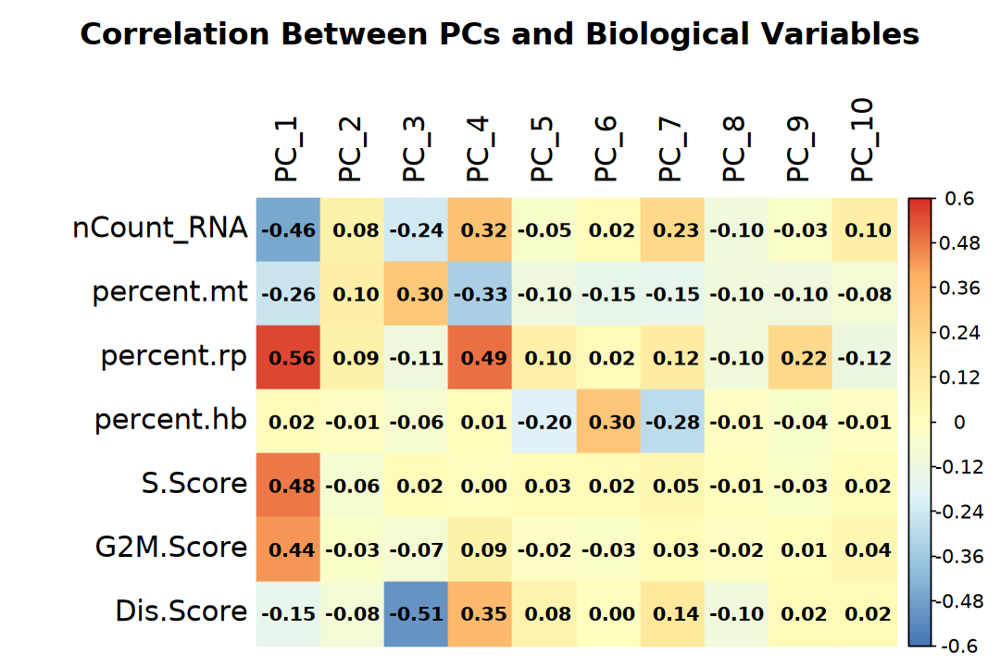

In [56]:
options(repr.plot.width = 9, repr.plot.height = 6)

gradient_colors <- colorRampPalette(
    c("#4575B4", "#91BFDB", "#E0F3F8", "#FFFFBF", 
      "#FEE090", "#FDAE61", "#D73027"))(200)

corrplot::corrplot(cors, method = "color",
                   col = gradient_colors, cl.cex = 1, 
                   col.lim = c(-.6, .6),
                   title = "Correlation Between PCs and Biological Variables",
                   cex.main = 1.6, col.main = "black",
                   tl.col = "black", tl.cex = 1.5,
                   addCoef.col = "black", number.cex = 1, 
                   is.corr = FALSE, mar = c(0, 0, 3, 0))

# 4. Normalization

In [57]:
sc.comb

An object of class Seurat 
27812 features across 18990 samples within 1 assay 
Active assay: RNA (27812 features, 0 variable features)
 8 layers present: counts.Donor1, counts.Donor2, counts.Donor3, counts.Donor4, data.Donor1, data.Donor2, data.Donor3, data.Donor4

## a). LogNormalize

In [58]:
sc.comb <- NormalizeData(sc.comb, verbose = FALSE)

In [59]:
sc.comb <- FindVariableFeatures(
    sc.comb, nfeatures = 3000, verbose = FALSE)

In [60]:
sc.temp <- ScaleData(
    sc.comb, features = Features(sc.comb), 
    vars.to.regress = "percent.mt", verbose = FALSE)
sc.temp

An object of class Seurat 
27812 features across 18990 samples within 1 assay 
Active assay: RNA (27812 features, 3000 variable features)
 9 layers present: counts.Donor1, counts.Donor2, counts.Donor3, counts.Donor4, data.Donor1, data.Donor2, data.Donor3, data.Donor4, scale.data

In [61]:
source("R/scale_data_chunked.R")

In [62]:
sc.comb <- scale_data_chunked(
    sc.comb, features = Features(sc.comb), 
    vars.to.regress = "percent.mt")
sc.comb

An object of class Seurat 
27812 features across 18990 samples within 1 assay 
Active assay: RNA (27812 features, 3000 variable features)
 9 layers present: counts.Donor1, counts.Donor2, counts.Donor3, counts.Donor4, data.Donor1, data.Donor2, data.Donor3, data.Donor4, scale.data

In [63]:
scaledata1 <- LayerData(sc.temp, assay = "RNA", layer = "scale.data")
scaledata2 <- LayerData(sc.comb, assay = "RNA", layer = "scale.data")

In [64]:
identical(scaledata1, scaledata2) && all(scaledata1 == scaledata2)

[1] TRUE

## b). SCTransform

In [65]:
sc.comb <- SCTransform(
    sc.comb, return.only.var.genes = FALSE,
    vars.to.regress = "percent.mt", verbose = FALSE)
sc.comb

An object of class Seurat 
53139 features across 18990 samples within 2 assays 
Active assay: SCT (25327 features, 3000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: RNA

In [66]:
DefaultAssay(sc.comb) <- "RNA"
sc.comb

An object of class Seurat 
53139 features across 18990 samples within 2 assays 
Active assay: RNA (27812 features, 3000 variable features)
 9 layers present: counts.Donor1, counts.Donor2, counts.Donor3, counts.Donor4, data.Donor1, data.Donor2, data.Donor3, data.Donor4, scale.data
 1 other assay present: SCT

In [67]:
saveRDS(sc.comb, file.path(
    data_dir, "result", "s4_normalization_seurat_V5.rds"))

# 5. Linear Dimensionality Reduction

In [68]:
sc.comb <- RunPCA(sc.comb, npcs = 50, verbose = FALSE)

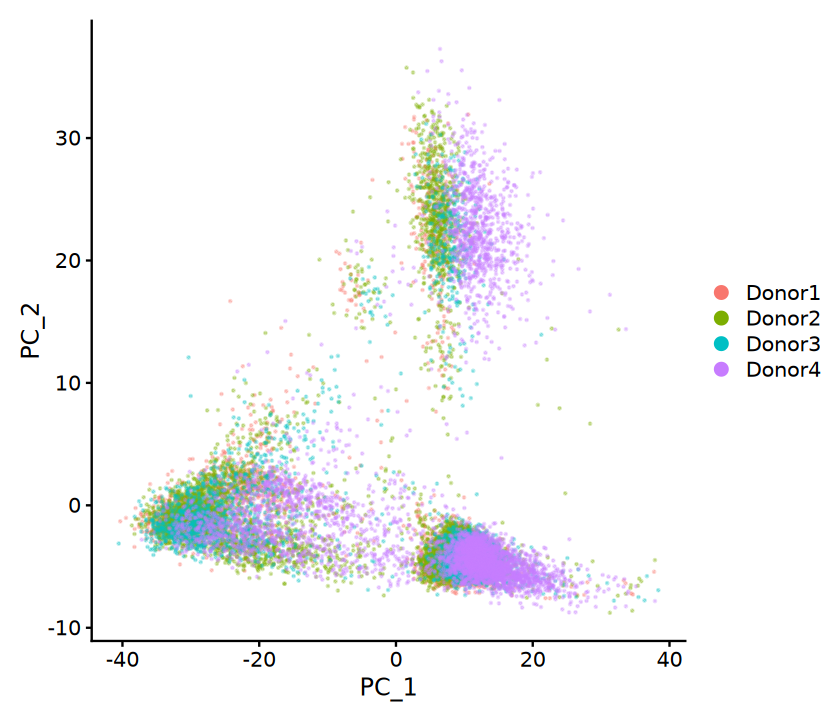

In [69]:
options(repr.plot.width = 7, repr.plot.height = 6)
DimPlot(sc.comb, reduction = "pca", alpha = 0.3)

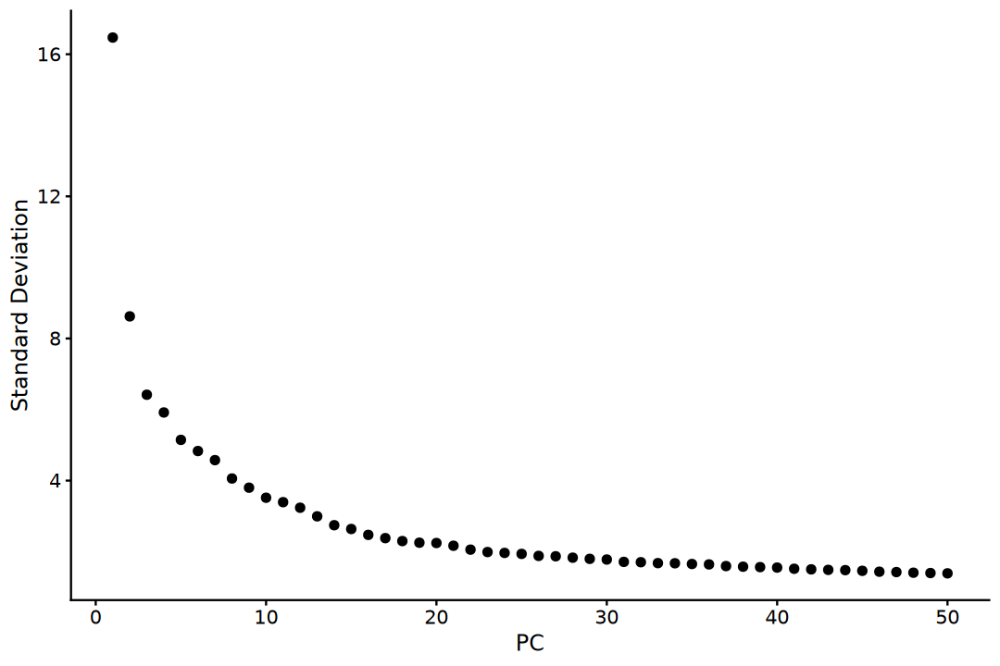

In [70]:
options(repr.plot.width = 9, repr.plot.height = 6)
ElbowPlot(sc.comb, ndims = 50)

In [71]:
# Estimating PCA dimensionality
pca_var <- sc.comb@reductions$pca@stdev^2
pca_con <- pca_var / sum(pca_var)
nPCs <- which(cumsum(pca_con) > 0.9 & pca_con < 0.05)[1]
print(nPCs)

[1] 24


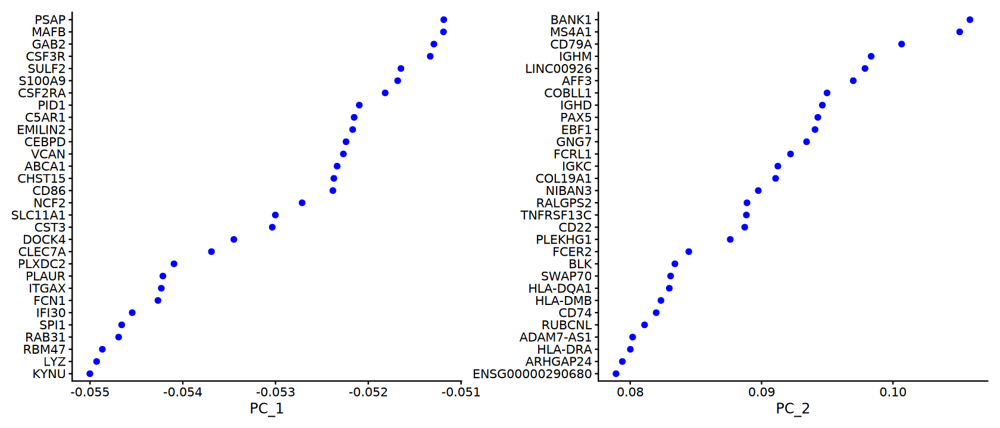

In [72]:
options(repr.plot.width = 14, repr.plot.height = 6)
VizDimLoadings(sc.comb, dims = 1:2, reduction = "pca", ncol = 2)

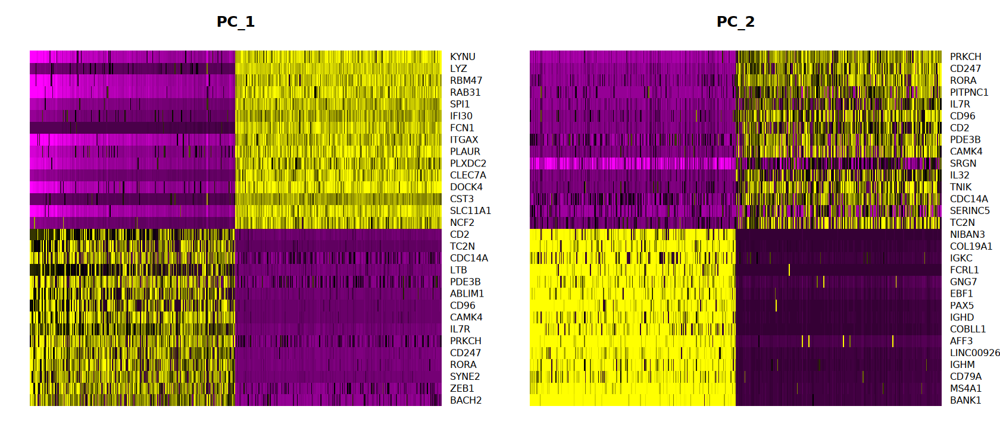

In [73]:
options(repr.plot.width = 14, repr.plot.height = 6)
DimHeatmap(sc.comb, dims = 1:2, cells = 500, balanced = TRUE)

In [74]:
source("R/compare_npcs_clustering.R")

In [75]:
plots <- compare_npcs_clustering(
    sc.comb, reduction = "pca", method = "umap")

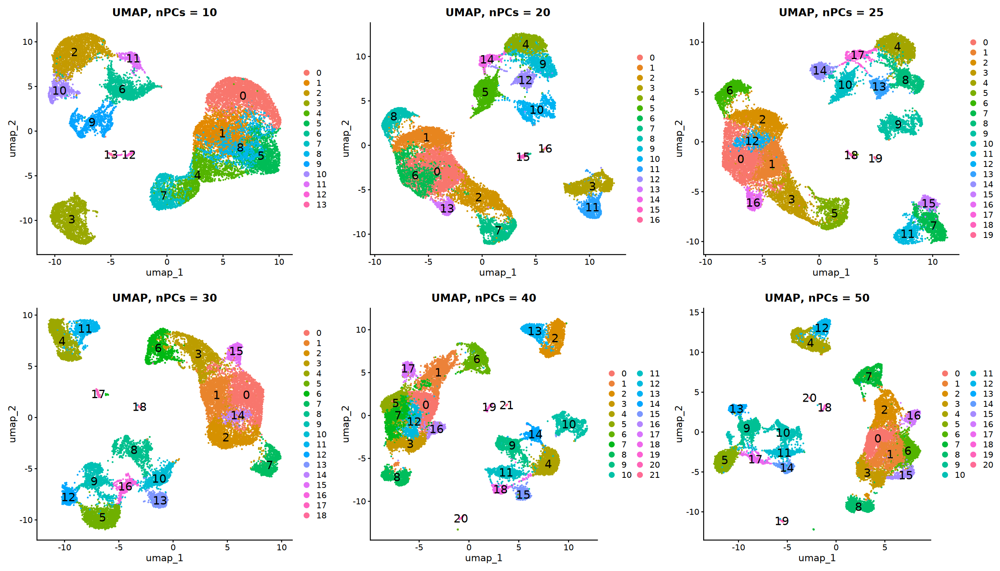

In [76]:
options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = plots, ncol = 3)

In [77]:
nPCs <- 30

# 6. Integration

In [78]:
sc.comb

An object of class Seurat 
53139 features across 18990 samples within 2 assays 
Active assay: RNA (27812 features, 3000 variable features)
 9 layers present: counts.Donor1, counts.Donor2, counts.Donor3, counts.Donor4, data.Donor1, data.Donor2, data.Donor3, data.Donor4, scale.data
 1 other assay present: SCT
 1 dimensional reduction calculated: pca

## a). CCA
Anchor-based canonical correlation analysis integration

In [79]:
sc.inte <- IntegrateLayers(
    sc.comb, method = CCAIntegration, orig.reduction = "pca", 
    new.reduction = "cca", verbose = FALSE)
sc.inte

An object of class Seurat 
53139 features across 18990 samples within 2 assays 
Active assay: RNA (27812 features, 3000 variable features)
 9 layers present: counts.Donor1, counts.Donor2, counts.Donor3, counts.Donor4, data.Donor1, data.Donor2, data.Donor3, data.Donor4, scale.data
 1 other assay present: SCT
 2 dimensional reductions calculated: pca, cca

## b). Harmony

In [80]:
suppressPackageStartupMessages(library(harmony))

In [81]:
sc.inte <- RunHarmony(
    sc.inte, "orig.ident", verbose = FALSE)
sc.inte

An object of class Seurat 
53139 features across 18990 samples within 2 assays 
Active assay: RNA (27812 features, 3000 variable features)
 9 layers present: counts.Donor1, counts.Donor2, counts.Donor3, counts.Donor4, data.Donor1, data.Donor2, data.Donor3, data.Donor4, scale.data
 1 other assay present: SCT
 3 dimensional reductions calculated: pca, cca, harmony

## Visualization

In [82]:
plot_inte_res <- function(obj, dims = 10, reduction) {
    
    obj <- RunUMAP(
        obj, dims = 1:dims, reduction = reduction, 
        verbose = FALSE)
    obj <- RunTSNE(
        obj, dims = 1:dims, reduction = reduction, 
        verbose = FALSE)

    p1 <- DimPlot(
        obj, reduction = reduction, group.by = "orig.ident", 
        pt.size = 0.1, alpha = 0.1)
    p2 <- DimPlot(
        obj, reduction = "umap", group.by = "orig.ident", 
        pt.size = 0.1, alpha = 0.1)
    p3 <- DimPlot(
        obj, reduction = "tsne", group.by = "orig.ident", 
        pt.size = 0.1, alpha = 0.1)
    
    plot_grid(p1, p2, p3, ncol = 1)
}

In [83]:
methods <- c("pca", "cca", "harmony")

pg_list <- lapply(methods, function(redu) {
    plot_inte_res(sc.inte, nPCs, redu)
})

In [84]:
titles <- c("non-integrate", "CCA", "Harmony")

title_list <- lapply(titles, function(text) {
    ggdraw() + draw_label(
        text, angle = 0, fontface = 'bold', size = 20)
})

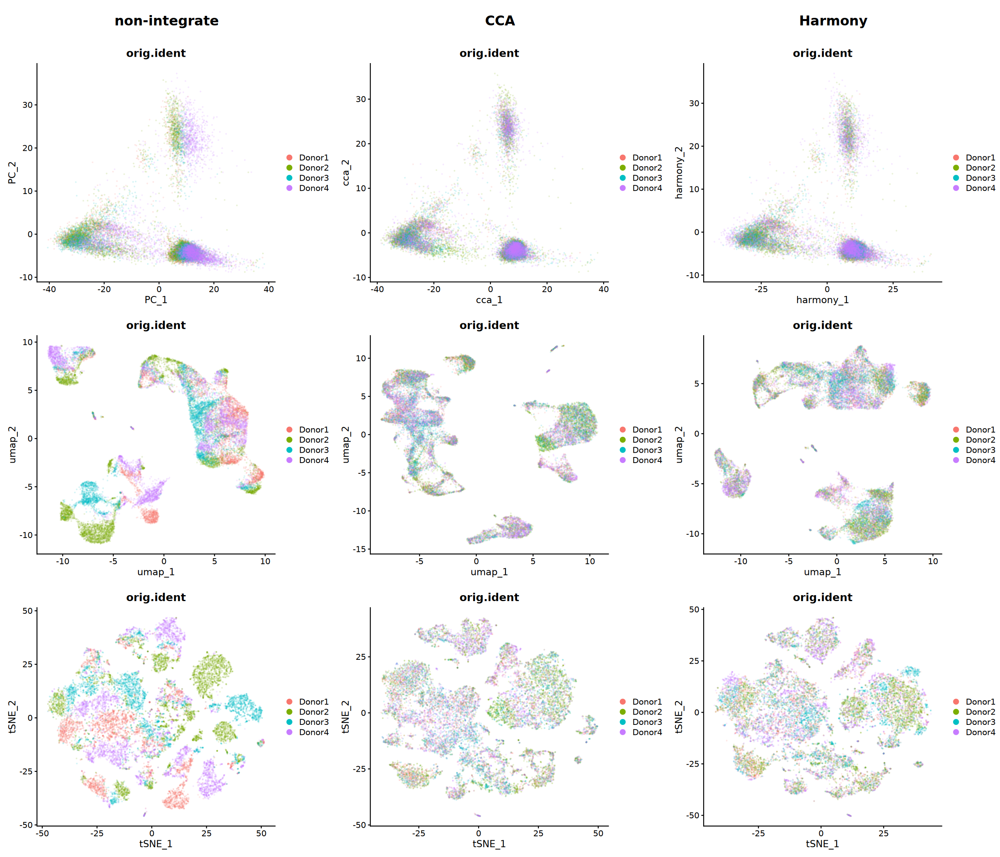

In [85]:
options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(
    plot_grid(plotlist = title_list, ncol = 3), 
    plot_grid(plotlist = pg_list, ncol = 3), 
    ncol = 1, rel_heights = c(0.05, 1))

In [86]:
inte <- "cca"

In [87]:
sc.inte <- JoinLayers(sc.inte)
sc.inte

An object of class Seurat 
53139 features across 18990 samples within 2 assays 
Active assay: RNA (27812 features, 3000 variable features)
 3 layers present: data, counts, scale.data
 1 other assay present: SCT
 3 dimensional reductions calculated: pca, cca, harmony

# 7. Neighborhood Graph Construction

In [88]:
sc.inte <- FindNeighbors(
    sc.inte, k.param = 20, reduction = inte, 
    dims = 1:nPCs, verbose = FALSE)

# 8. Non-linear Dimensionality Reduction

In [89]:
sc.inte <- RunUMAP(
    sc.inte, dims = 1:nPCs, reduction = inte, 
    verbose = FALSE)

In [90]:
sc.inte <- RunTSNE(
    sc.inte, dims = 1:nPCs, reduction = inte,
    verbose = FALSE)

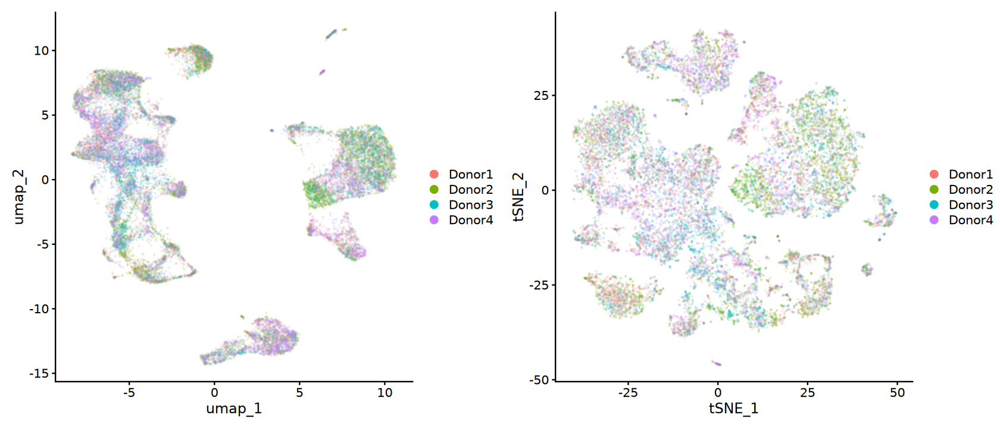

In [91]:
p1 <- DimPlot(
    sc.inte, reduction = "umap", pt.size = 0.1, alpha = 0.1)
p2 <- DimPlot(
    sc.inte, reduction = "tsne", pt.size = 0.1, alpha = 0.1)

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

# 9. Clustering

In [92]:
source("R/scan_clustering_resolution.R")

In [93]:
cluster_list <- scan_clustering_resolution(
    sc.inte, reduction = inte, dims = nPCs,
    resolution = seq(0.1, 0.9, 0.1))

Registered S3 method overwritten by 'pROC':
  method   from            
  plot.roc spatstat.explore



In [94]:
metrics_df <- cluster_list$metrics |>
    mutate(accuracy = round(accuracy * 100, 2), 
           f1 = round(f1 * 100, 2),
           silhouette = round(silhouette * 100, 2),
           modularity = round(modularity * 100, 2))
metrics_df

,resolution,n_cluster,accuracy,f1,silhouette,modularity
,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
res_0.1,0.1,11,71.96,75.12,20.40,82.63
res_0.2,0.2,15,68.23,92.41,22.79,84.02
res_0.3,0.3,16,62.38,71.60,21.19,85.33
res_0.4,0.4,17,60.90,70.58,22.28,86.23
res_0.5,0.5,19,53.16,85.97,20.90,87.07
res_0.6,0.6,20,51.19,84.77,20.36,87.17
res_0.7,0.7,20,47.35,83.45,20.34,87.18
res_0.8,0.8,23,47.18,88.96,20.71,87.21
res_0.9,0.9,24,40.90,73.05,18.48,87.21


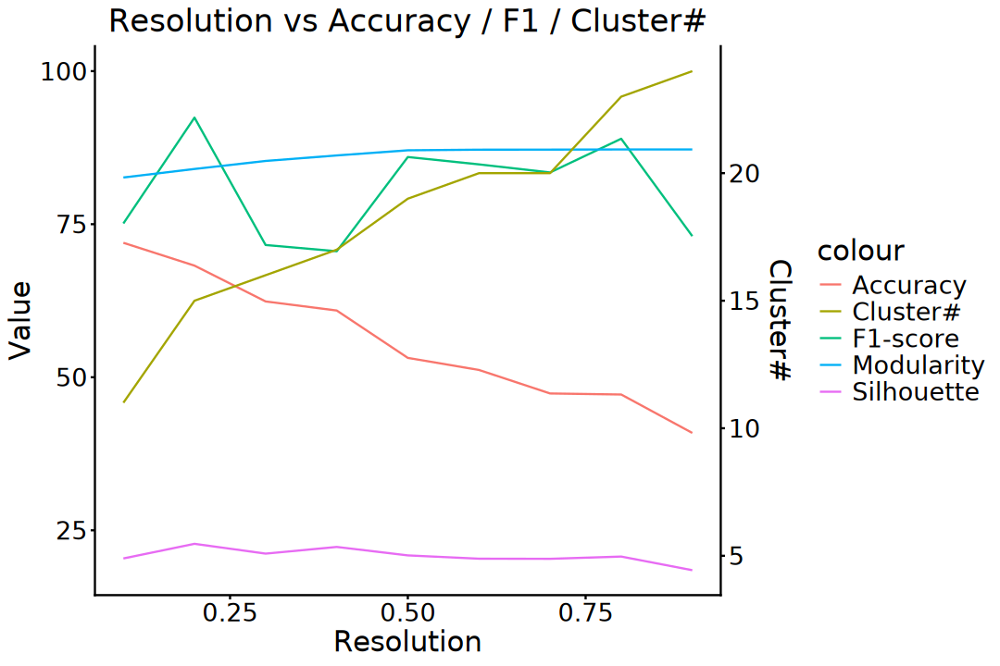

In [95]:
options(repr.plot.width = 9, repr.plot.height = 6)
ggplot(metrics_df, aes(x = resolution)) +
    geom_line(aes(y = accuracy, color = "Accuracy")) +
    geom_line(aes(y = f1, color = "F1-score")) +
    geom_line(aes(y = silhouette, color = "Silhouette")) +
    geom_line(aes(y = modularity, color = "Modularity")) +
    geom_line(aes(y = n_cluster/ max(n_cluster)*100, 
                  color = "Cluster#")) +
    scale_y_continuous(
        name = "Value", 
        sec.axis = sec_axis(
            ~./100*max(metrics_df$n_cluster), name = "Cluster#")) +
    ggtitle("Resolution vs Accuracy / F1 / Cluster#") + 
    labs(x = "Resolution") +
    theme_classic() +
    theme(plot.title =  element_text(size = 20, hjust = 0.5),
          axis.title = element_text(size = 18),
          axis.text = element_text(size = 16),
          legend.title = element_text(size = 18),
          legend.text = element_text(size = 16))

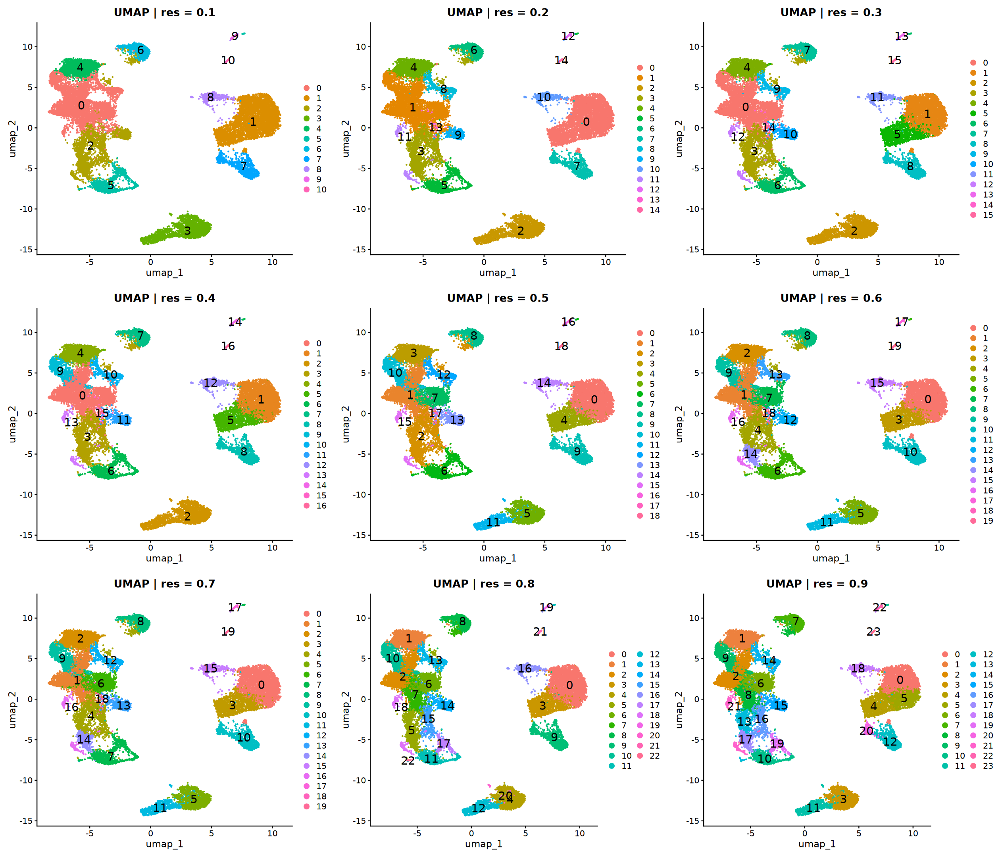

In [96]:
options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(plotlist = cluster_list$umap, ncol = 3)

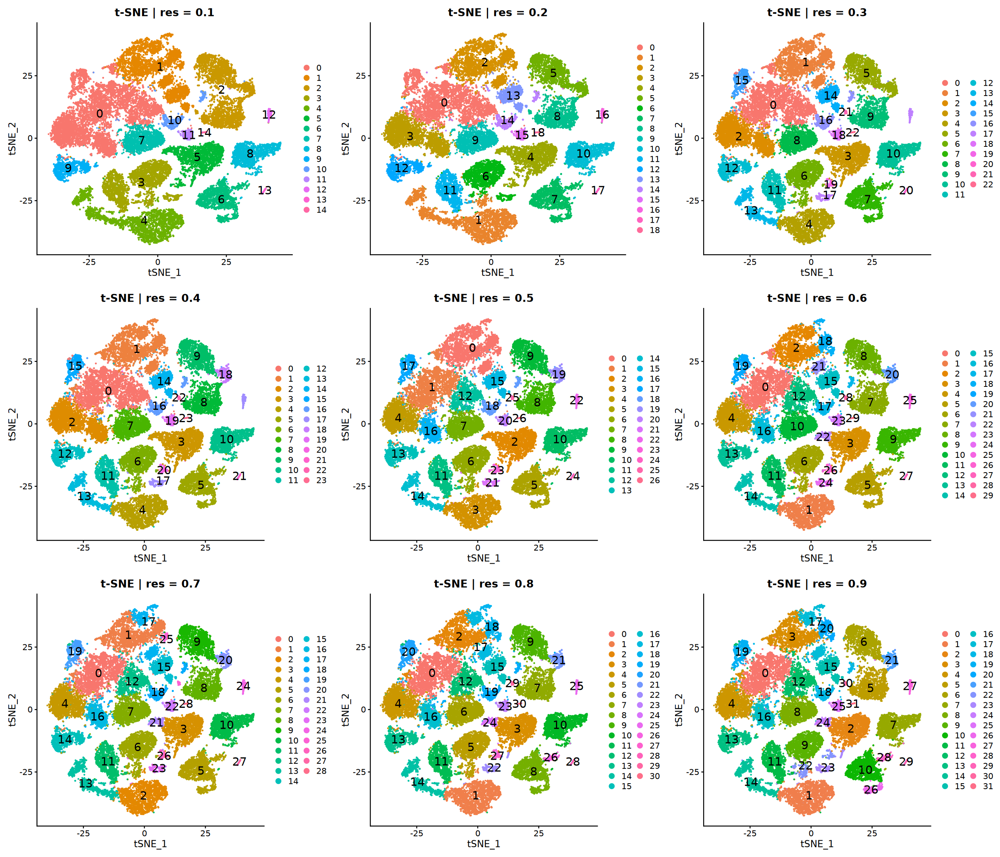

In [81]:
options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(plotlist = cluster_list$tsne, ncol = 3)

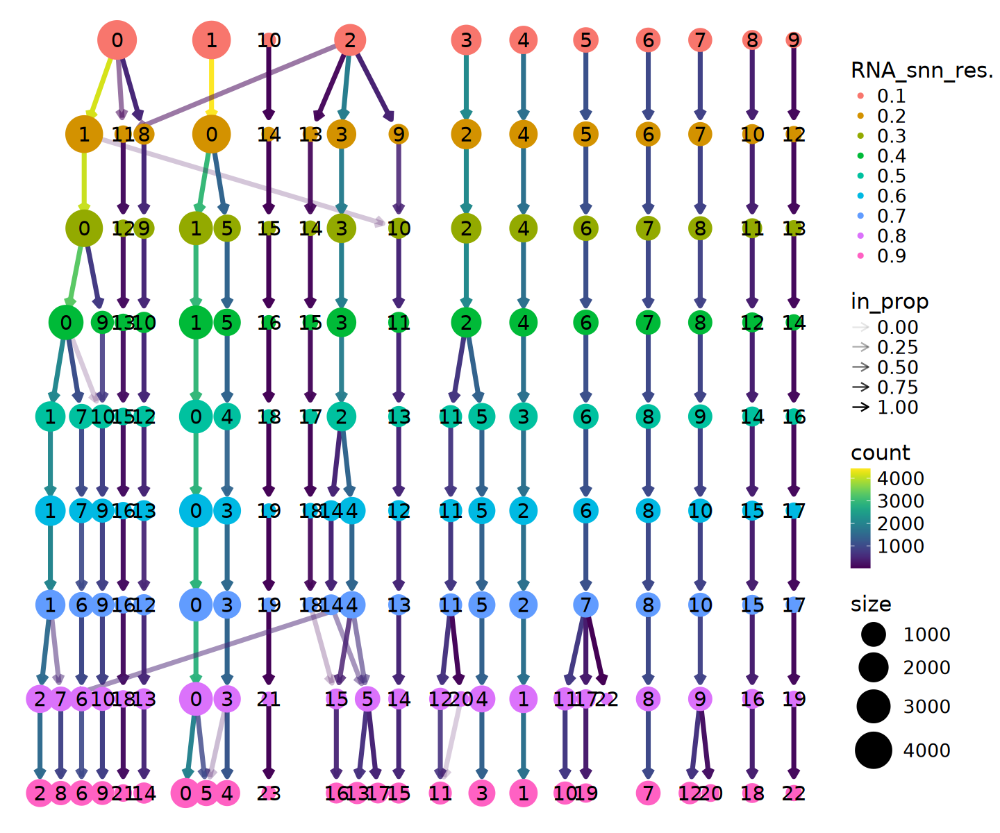

In [97]:
options(repr.plot.width = 12, repr.plot.height = 10)
cluster_list$clustree

In [98]:
sc.inte <- FindClusters(
    sc.inte, resolution = 0.7, verbose = FALSE)

In [99]:
# n.neighbors 5 ~ 50, 30
# min.dist 0.001 ~ 0.5, 0.3
plot_umap_params <- function(obj, dims = 10, nn = 30, md = 0.3) {    
    RunUMAP(obj, dims = 1:dims, reduction = inte, 
            n.neighbors = nn, min.dist = md, verbose = FALSE) |>
    DimPlot(reduction = "umap", group.by = "seurat_clusters",
            label = TRUE, label.size = 6, repel = FALSE) +
        ggtitle(paste0("n.neighbors = ", nn, "\nmin.dist = ", md))
}

In [100]:
p1 <- lapply(
    c(10, 30, 50), plot_umap_params, 
    obj = sc.inte, dims = nPCs, md = 0.3)
p2 <- lapply(
    c(0.01, 0.3, 0.5), plot_umap_params, 
    obj = sc.inte, dims = nPCs, nn = 30)

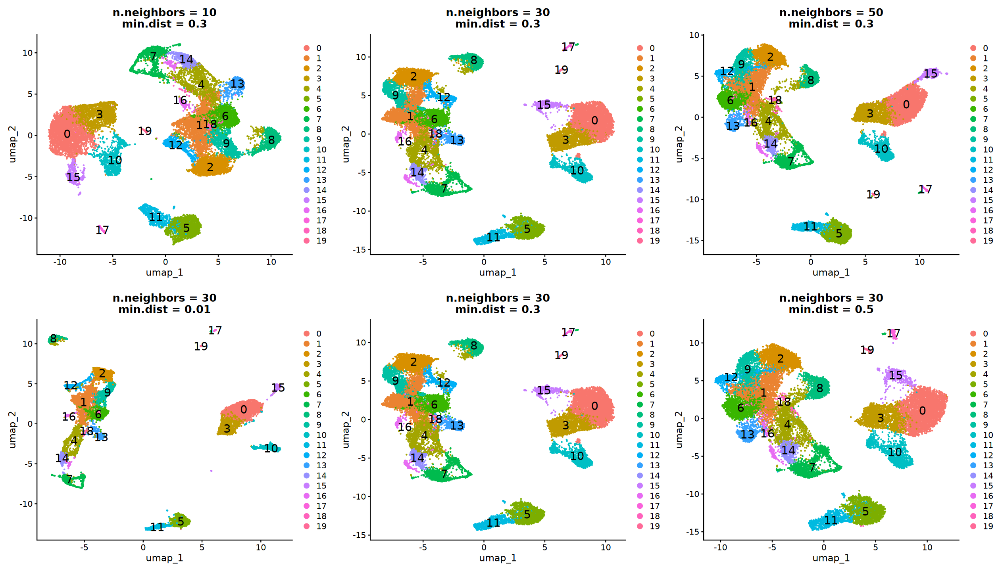

In [101]:
options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plot_grid(plotlist = p1, ncol = 3),
          plot_grid(plotlist = p2, ncol = 3), ncol = 1)

In [102]:
# perplexity 5 ~ 50, 30
plot_tsne_params <- function(obj, dims = 10, perplexity = 30) {    
    RunTSNE(obj, dims = 1:dims, reduction = inte, 
            perplexity = perplexity, verbose = FALSE) |>
    DimPlot(reduction = "tsne", group.by = "seurat_clusters",
            label = TRUE, label.size = 6, repel = FALSE) +
        ggtitle(paste0("perplexity = ", perplexity))
}

In [103]:
p1 <- lapply(
    c(10, 30, 50), plot_tsne_params, 
    obj = sc.inte, dims = nPCs)

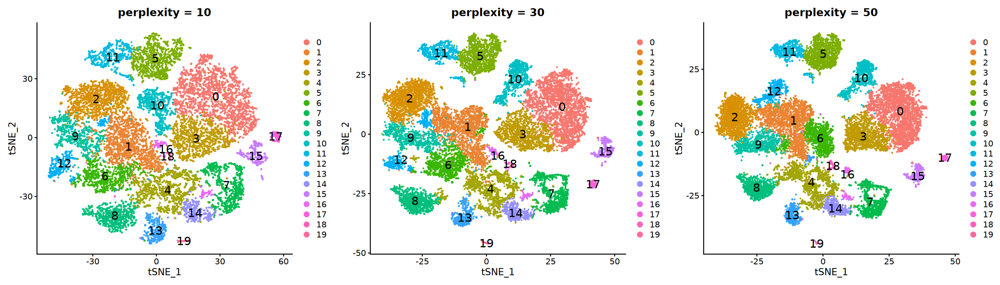

In [104]:
options(repr.plot.width = 21, repr.plot.height = 6)
plot_grid(plotlist = p1, ncol = 3)

In [105]:
sc.inte <- RunUMAP(
    sc.inte, dims = 1:nPCs, reduction = inte,
    n.neighbors = 30, min.dist = 0.3, verbose = FALSE)

In [106]:
sc.inte <- RunTSNE(
    sc.inte, dims = 1:nPCs, reduction = inte, 
    perplexity = 30, verbose = FALSE)

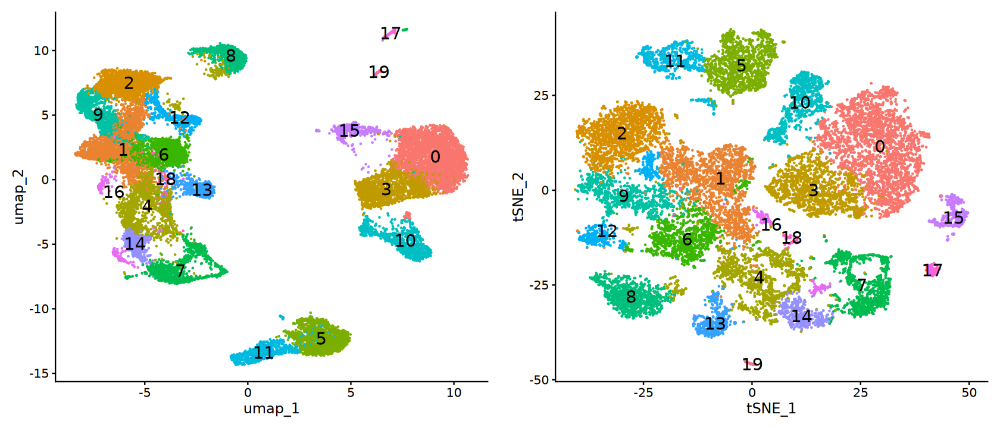

In [107]:
p1 <- DimPlot(
    sc.inte, reduction = "umap", label = TRUE,
    label.size = 6) & NoLegend()
p2 <- DimPlot(
    sc.inte, reduction = "tsne", label = TRUE,
    label.size = 6) & NoLegend()

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

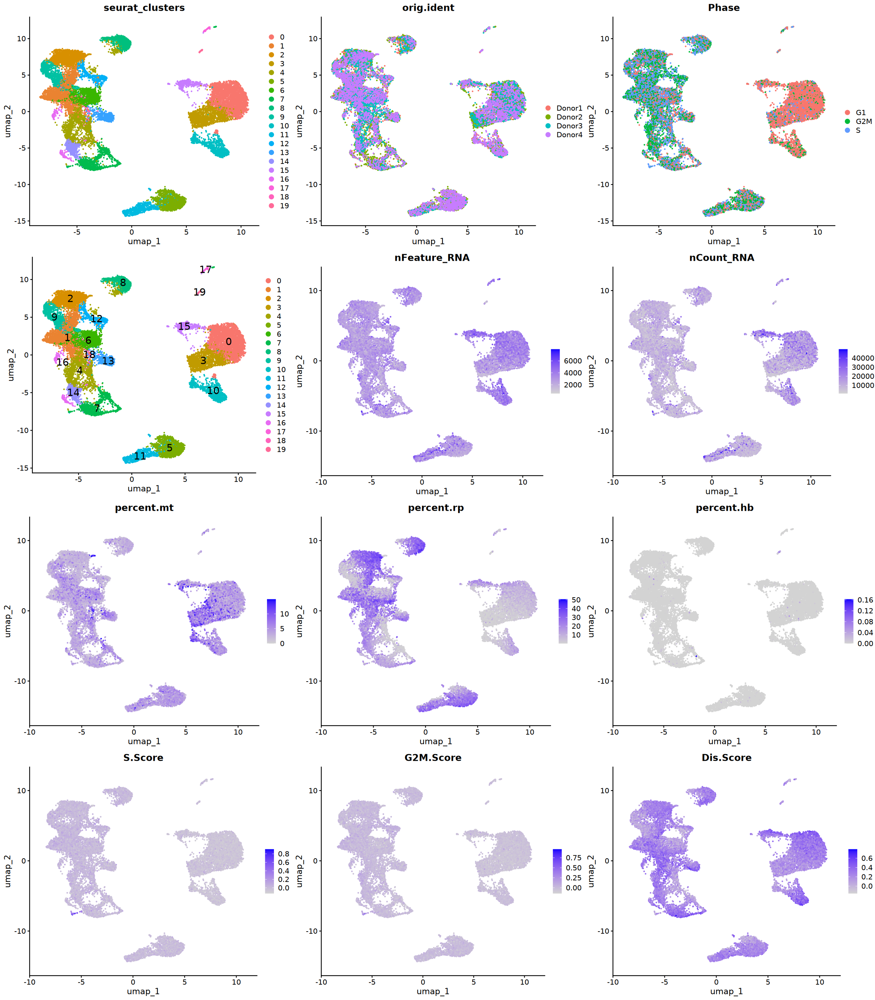

In [108]:
p1 <- DimPlot(
    sc.inte, reduction = "umap", combine = FALSE,
    group.by = c("seurat_clusters", "orig.ident", "Phase"))
p2 <- DimPlot(
    sc.inte, reduction = "umap", label = TRUE,
    label.size = 6)
p3 <- FeaturePlot(
    sc.inte, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA"))
p4 <- FeaturePlot(
    sc.inte, reduction = "umap", combine = FALSE,
    features = c("percent.mt", "percent.rp", "percent.hb", 
                 "S.Score", "G2M.Score", "Dis.Score"))

options(repr.plot.width = 21, repr.plot.height = 24)
plot_grid(plotlist = c(p1, p2, p3, p4), ncol = 3)

In [109]:
sc.inte

An object of class Seurat 
53139 features across 18990 samples within 2 assays 
Active assay: RNA (27812 features, 3000 variable features)
 3 layers present: data, counts, scale.data
 1 other assay present: SCT
 5 dimensional reductions calculated: pca, cca, harmony, umap, tsne

# 10. Cluster Biomarkers

In [110]:
sc.markers <- FindAllMarkers(
    sc.inte, logfc.threshold = log2(1.2), min.pct = 0.25,
    only.pos = TRUE, verbose = FALSE)

In [111]:
sc.markers.filt <- sc.markers |> 
    filter(p_val_adj < 0.01, 
           avg_log2FC > log2(1.2), 
           pct.1 - pct.2 > 0.2)

In [112]:
sc.markers.filt |> 
    group_by(cluster) |> 
    summarise(length(gene)) |>
    t()

cluster,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
length(gene),2015,175,197,767,127,322,199,282,382,149,1450,687,161,205,270,1910,126,1668,2,500


In [113]:
top10 <- sc.markers.filt |> 
    group_by(cluster) |> 
    top_n(10, wt = avg_log2FC)

top3 <- sc.markers.filt |> 
    group_by(cluster) |> 
    top_n(3, wt = avg_log2FC)

## Visualization

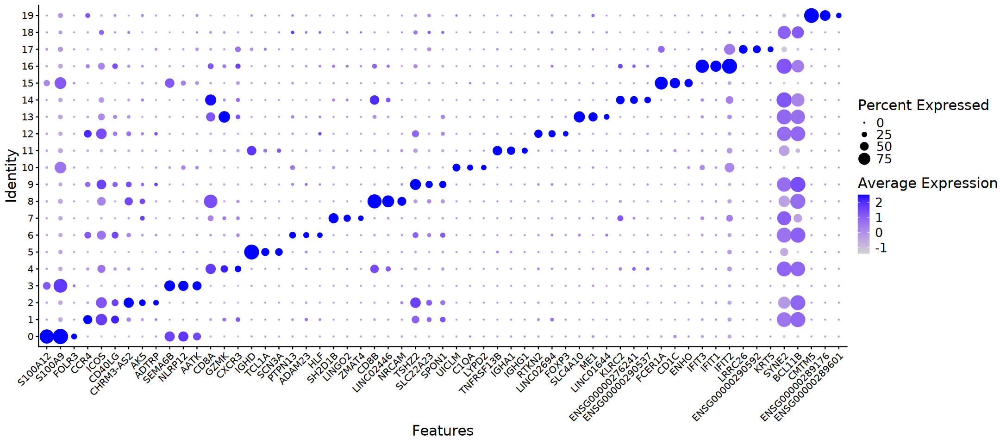

In [114]:
options(repr.plot.width = 18, repr.plot.height = 8)
DotPlot(sc.inte, features = unique(top3$gene), dot.scale = 8) + 
    RotatedAxis() + 
    theme(axis.title = element_text(size = 18),
          axis.text = element_text(size = 12),
          legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16))

In [115]:
plot_dir <- file.path(
    data_dir, "visualization", "p7.1_cluster_top10_genes")

if (!dir.exists(plot_dir)) {
    dir.create(plot_dir, recursive = TRUE)
}

In [116]:
for (index in seq(1:length(top10$gene))) {
    p1 <- VlnPlot(sc.inte, features = top10$gene[index])
    p2 <- FeaturePlot(
        sc.inte, reduction = "umap", features = top10$gene[index])
    p3 <- FeaturePlot(
        sc.inte, reduction = "tsne", features = top10$gene[index])
    pg <- plot_grid(p1, plot_grid(p2, p3, ncol = 2), ncol = 1)
    
    file.path(plot_dir, paste0(
        "cluster_", top10$cluster[index], "_", top10$gene[index], ".png")) |>
        ggsave(plot = pg, width = 9, height = 8)
}

In [117]:
ht <- DoHeatmap(sc.comb, features = top3$gene, 
                slot = "scale.data", size = 8) +
    # scale_fill_gradientn(colors = PurpleAndYellow()) +
    theme(axis.text = element_text(size = 12),
          legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16))

file.path(data_dir, "visualization", "p7.2_DEG_Top3_DoHeatmap.png") |>
    ggsave(plot = ht, width = 24, height = 16)

# 11. Cell-type Annotation

## a). Automatic

In [118]:
suppressPackageStartupMessages(library(SingleR))

In [119]:
ref_pbmc <- file.path(
    "~/data1/single_cell_dataset/PBMCs/Hs_PBMC_GSE164378", 
    "matrix", "RNA_3P", "RNA") |>
    Read10X()

In [120]:
ref_metadata <- file.path(
    "~/data1/single_cell_dataset/PBMCs/Hs_PBMC_GSE164378", 
    "GSE164378_sc.meta.data_3P.csv.gz") |>
    read.csv(header = TRUE, row.names = 1) |>
    select(celltype.l1, celltype.l2, celltype.l3)

In [121]:
ref_pbmc <- SingleCellExperiment(
    list(counts = ref_pbmc), 
    colData = ref_metadata)

ref_pbmc <- scuttle::logNormCounts(ref_pbmc)

ref_pbmc

class: SingleCellExperiment 
dim: 33538 161764 
metadata(0):
assays(2): counts logcounts
rownames(33538): MIR1302-2HG FAM138A ... AC213203.1 FAM231C
rowData names(0):
colnames(161764): L1_AAACCCAAGAAACTCA L1_AAACCCAAGACATACA ...
  E2L8_TTTGTTGGTTGGCTAT E2L8_TTTGTTGTCTCATGGA
colData names(4): celltype.l1 celltype.l2 celltype.l3 sizeFactor
reducedDimNames(0):
mainExpName: NULL
altExpNames(0):

In [122]:
# SingleR performs the prediction of celltypes for each cluster
celltype.SingleR <- LayerData(
    sc.inte, assay = "RNA", layer = "data") |>
    SingleR(ref = ref_pbmc, labels = ref_pbmc$celltype.l2, 
            clusters = sc.inte$seurat_clusters,
            de.method = "wilcox")

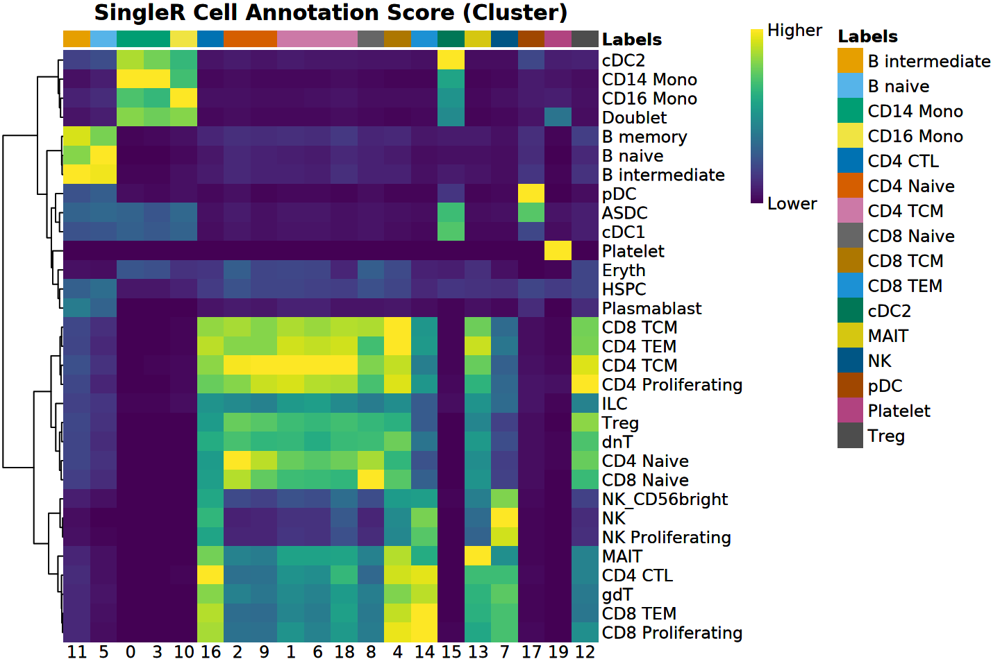

In [123]:
options(repr.plot.width = 12, repr.plot.height = 8)
plotScoreHeatmap(
    celltype.SingleR, show_colnames = TRUE, 
    main = "SingleR Cell Annotation Score (Cluster)",
    angle_col = 0, fontsize = 14)

In [124]:
sc.inte$celltype.SingleR <- 
    celltype.SingleR$labels[sc.inte$seurat_clusters]

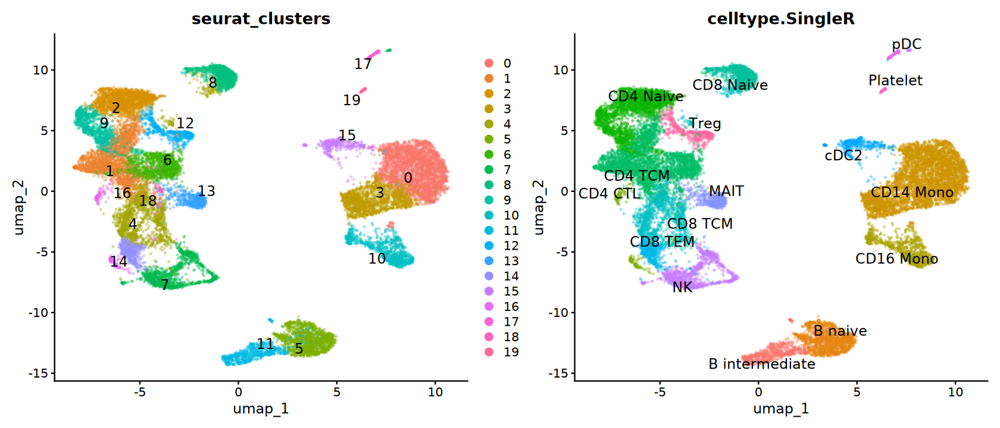

In [125]:
options(repr.plot.width = 14, repr.plot.height = 6)
DimPlot(sc.inte, reduction = "umap", 
        group.by = c("seurat_clusters", "celltype.SingleR"), 
        label = TRUE, repel = TRUE, label.size = 5, 
        pt.size = 0.3,  alpha = 0.3) + 
    NoLegend()

## b). Manual

In [126]:
gene_list <- sc.markers.filt |> 
    group_by(cluster) |> 
    top_n(10, wt = avg_log2FC) |>
    summarise(genes = paste0('"', gene, '"', collapse = ", ")) |>
    mutate(out = paste0("cluster_", cluster, ": ", genes)) |> 
    pull(out)

In [127]:
gene_list |> cat(sep = "\n")

cluster_0: "S100A12", "CD14", "S100A8", "S100A9", "RBP7", "CLEC4E", "FCGR1A", "MPHOSPH10P1", "FOLR3", "ALDH1A1"
cluster_1: "TRAT1", "CD2", "CD5", "CCR4", "ICOS", "ITM2A", "GATA3", "CD40LG", "DUSP4", "PASK"
cluster_2: "LEF1", "FHIT", "CHRM3-AS2", "MAL", "PRKCQ-AS1", "AK5", "ADTRP", "ENSG00000289707", "LEF1-AS1", "LYPD3"
cluster_3: "FCAR", "PPARG", "FAM20C", "SEMA6B", "NLRP12", "AATK", "RNF152", "ADORA2B", "NTSR1", "TNS1"
cluster_4: "CCL5", "CD8A", "CD8B", "GZMK", "MCOLN2", "TRGC2", "C1orf21", "CXCR3", "LINC01871", "KLRG1"
cluster_5: "IGHD", "COL19A1", "FCRL1", "FCER2", "LIX1-AS1", "TCL1A", "PCDH9", "SCN3A", "LINC02397", "KLHL14"
cluster_6: "KIF5C", "CCR6", "TNFRSF4", "PTPN13", "ENSG00000227240", "ADAM23", "HLF", "ELOVL4", "TCP10L", "ZDHHC11B"
cluster_7: "GNLY", "KLRF1", "SH2D1B", "NCAM1", "BNC2", "LINGO2", "XCL2", "B3GNT7", "KIR2DS4", "ZMAT4"
cluster_8: "CD8B", "LINC02446", "APBA2", "NRCAM", "PTPRK", "S100B", "LRRN3", "ENSG00000290109", "TTTY14", "CLEC11A"
cluster_9: "ANK3", "TSHZ2", "F

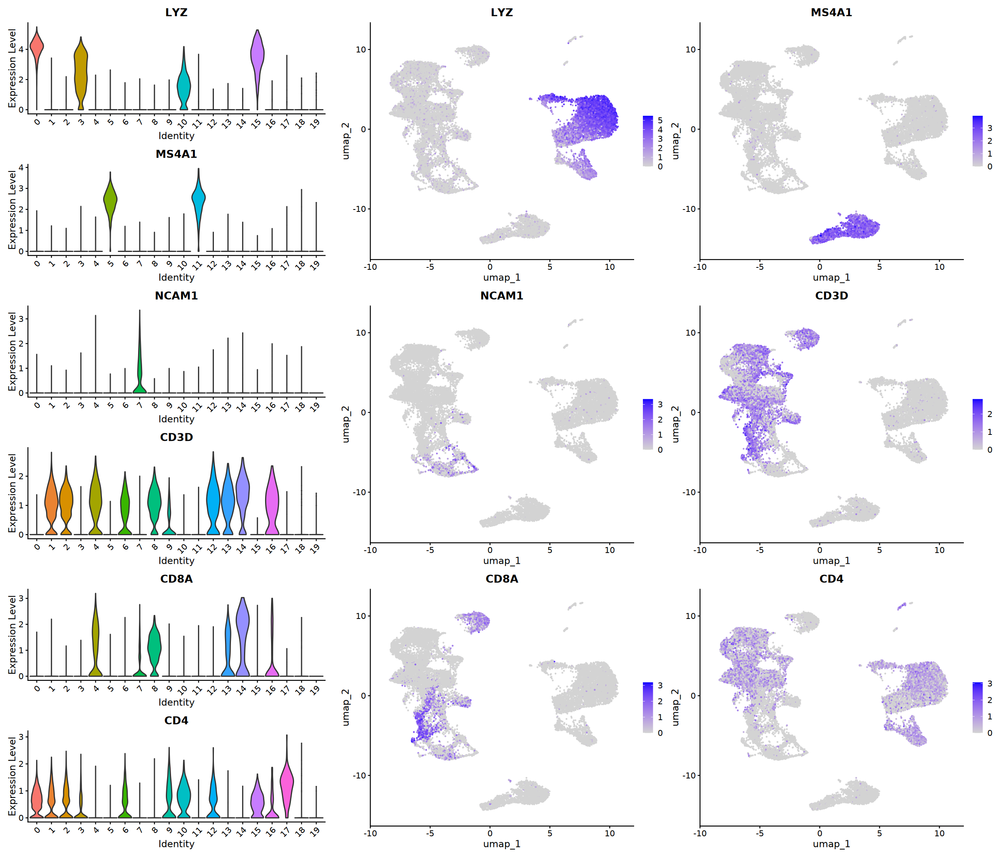

In [128]:
geneset <- c("LYZ", "MS4A1", "NCAM1", "CD3D", "CD8A", "CD4")
p1 <- VlnPlot(
    sc.inte, features = geneset, ncol = 1, pt.size = 0)
p2 <- FeaturePlot(
    sc.inte, reduction = "umap", features = geneset, ncol = 2)

options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(p1, p2, ncol = 2, rel_widths = c(1, 2))

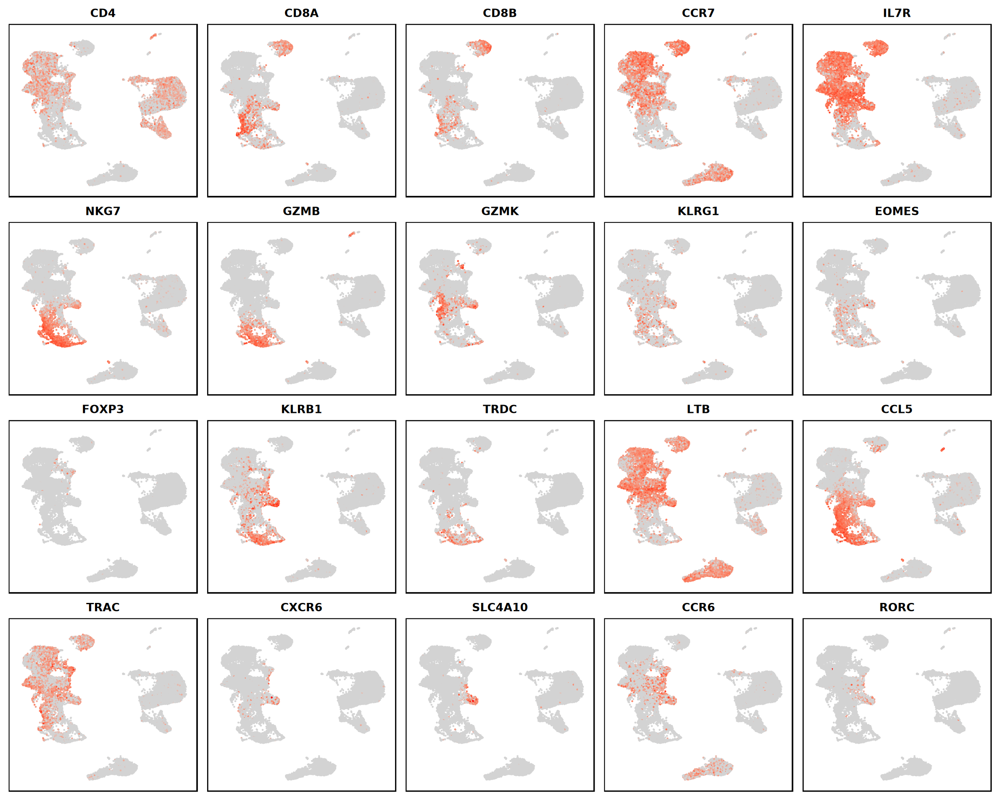

In [129]:
geneset <- c("CD4", "CD8A", "CD8B", "CCR7", "IL7R", 
             "NKG7", "GZMB", "GZMK", "KLRG1", "EOMES", 
             "FOXP3", "KLRB1", "TRDC", "LTB", "CCL5",
             "TRAC", "CXCR6", "SLC4A10", "CCR6", "RORC")

options(repr.plot.width = 20, repr.plot.height = 16)
FeaturePlot(sc.inte, features = geneset, reduction = "umap", 
            cols = c("lightgrey", 'red'), ncol = 5) & 
    NoLegend() & NoAxes() &
    theme(panel.border = element_rect(color = "black", linewidth = 1))

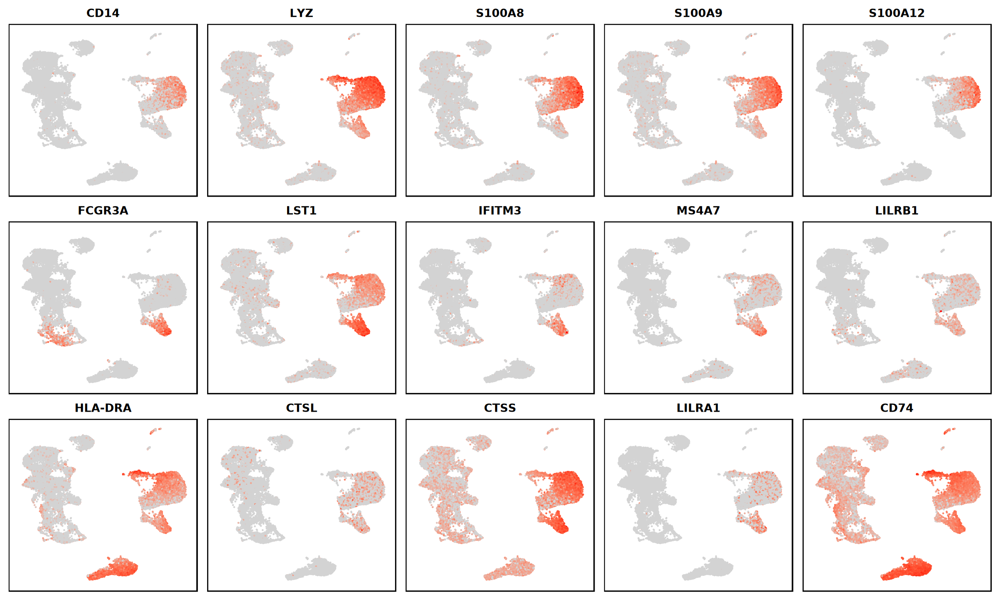

In [130]:
# Classical monocytes: "CD14", "LYZ", "S100A8", "S100A9", "S100A12"
# Non-classical monocytes: "FCGR3A", "LST1", "IFITM3", "MS4A7", "LILRB1"
# Intermediate monocytes: "CD14", "FCGR3A", "HLA-DRA", "HLA-DPB1", "CTSL", "CTSS", "LILRA1", "CD74"

geneset <- c("CD14", "LYZ", "S100A8", "S100A9", "S100A12",
             "FCGR3A", "LST1", "IFITM3", "MS4A7", "LILRB1",
             "HLA-DRA", "CTSL", "CTSS", "LILRA1", "CD74")

options(repr.plot.width = 20, repr.plot.height = 12)
FeaturePlot(sc.inte, features = geneset, reduction = "umap", 
            cols = c("lightgrey", 'red'), ncol = 5) & 
    NoLegend() & NoAxes() &
    theme(panel.border = element_rect(color = "black", linewidth = 1))

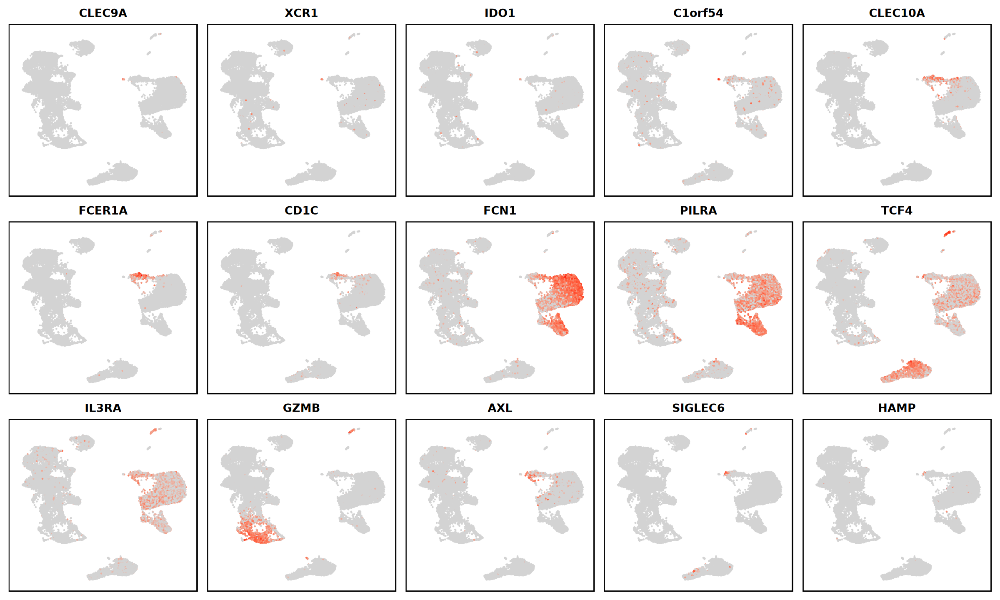

In [131]:
# cDC1: "CLEC9A", "XCR1", "IDO1", "C1orf54"
# cDC2: "CD1C", "FCN1", "PILRA"
# pDC: "GZMB", "TCF4", "IL3RA", "CLEC4C"
# ASDC: "AXL", "SIGLEC6", "HAMP"

geneset <- c("CLEC9A", "XCR1", "IDO1", "C1orf54",
             "CLEC10A", "FCER1A", "CD1C", "FCN1", "PILRA",
             "TCF4", "IL3RA", "GZMB",
             "AXL", "SIGLEC6", "HAMP")

options(repr.plot.width = 20, repr.plot.height = 12)
FeaturePlot(sc.inte, features = geneset, reduction = "umap", 
            cols = c("lightgrey", 'red'), ncol = 5) & 
    NoLegend() & NoAxes() &
    theme(panel.border = element_rect(color = "black", linewidth = 1))

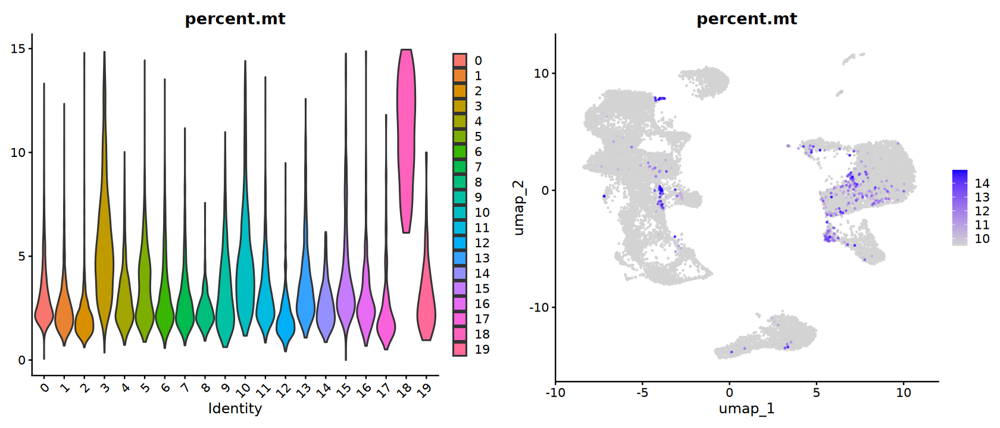

In [132]:
options(repr.plot.width = 14, repr.plot.height = 6)
p1 <- VlnPlot(
    sc.inte, features = "percent.mt", pt.size = 0)
p2 <- FeaturePlot(
    sc.inte, reduction = "umap", features = "percent.mt",
    min.cutoff = "q98", order = TRUE)

plot_grid(plotlist = c(p1, p2), ncol = 2)

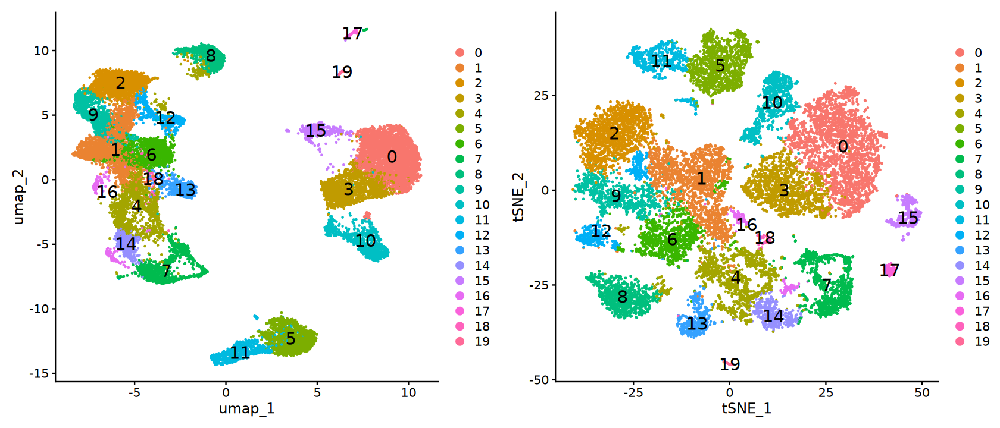

In [133]:
p1 <- DimPlot(
    sc.inte, reduction = "umap", label = TRUE, 
    label.size = 6, repel = FALSE)
p2 <- DimPlot(
    sc.inte, reduction = "tsne", label = TRUE, 
    label.size = 6, repel = FALSE)

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

In [134]:
# Cell annotation with ChatGPT assistance
cluster2celltype <- c(
    "0" = "Classical Monocytes", "1" = "Activated CD4 T", "2" = "Naïve CD4 T",
    "3" = "Classical Monocytes", "4" = "Cytotoxic CD8 T", "5" = "Naïve B",
    "6" = "Activated CD4 T", "7" = "NK Cells", "8" = "Naïve CD8 T",
    "9" = "Naïve CD4 T", "10" = "Non-classical Monocytes", "11" = "Plasmablast",
    "12" = "Tregs", "13" = "MAIT", "14" = "Terminally Cytotoxic CD8 T",
    "15" = "cDC2", "16" = "Activated CD4 T", "17" = "pDC",
    "18" = "High-mito", "19" = "Platelet")

In [135]:
# Cell annotation with ChatGPT assistance
group2celltype <- c(
    "0" = "Myeloids", "1" = "T", "2" = "T",
    "3" = "Myeloids", "4" = "T", "5" = "B",
    "6" = "T", "7" = "NK", "8" = "T",
    "9" = "T", "10" = "Myeloids", "11" = "B",
    "12" = "T", "13" = "T", "14" = "T",
    "15" = "Myeloids", "16" = "T", "17" = "Myeloids",
    "18" = "High-mito", "19" = "Platelet")

In [136]:
sc.inte@meta.data$celltype <- 
    cluster2celltype[as.character(sc.inte$seurat_clusters)]
sc.inte@meta.data$grouptype <- 
    group2celltype[as.character(sc.inte$seurat_clusters)]

sc.inte <- RenameIdents(sc.inte, cluster2celltype)

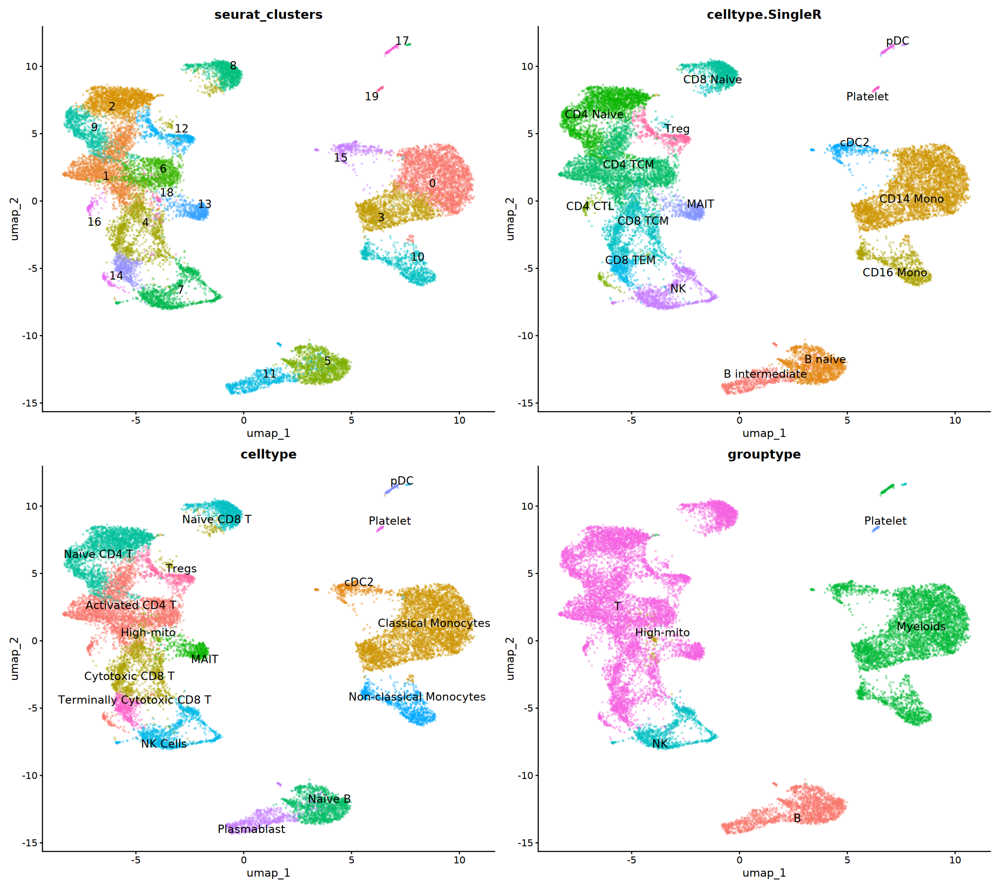

In [137]:
options(repr.plot.width = 18, repr.plot.height = 16)
DimPlot(sc.inte, reduction = "umap",
        group.by = c("seurat_clusters", "celltype.SingleR",
                     "celltype", "grouptype"), 
        label = TRUE, repel = TRUE, label.size = 5, 
        pt.size = 0.3,  alpha = 0.3) & 
    NoLegend()

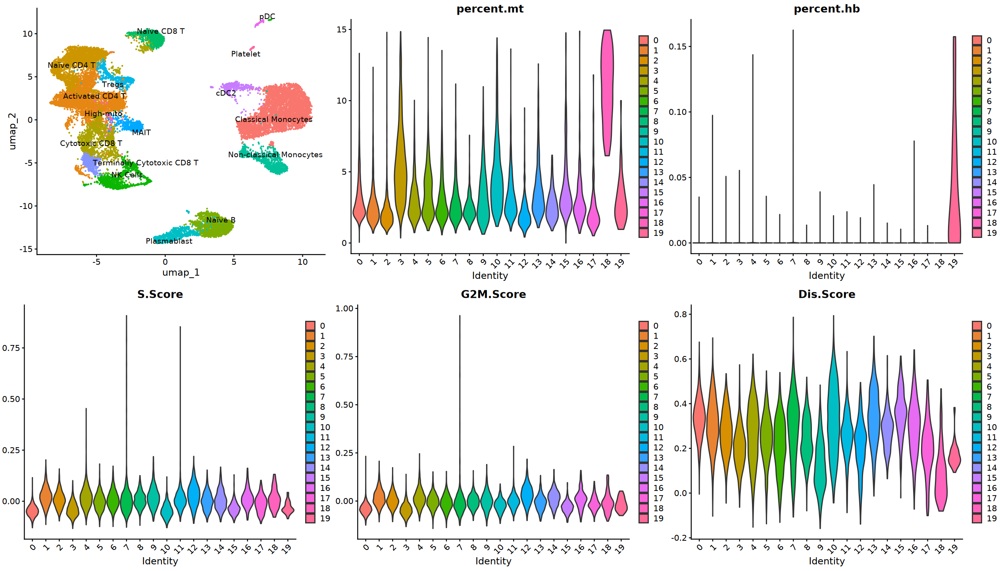

In [138]:
p1 <- DimPlot(
    sc.inte, reduction = "umap", label = TRUE, 
    label.size = 4, repel = TRUE) & NoLegend()
p2 <- VlnPlot(
    sc.inte, features = c("percent.mt", "percent.hb"), 
    group.by = "seurat_clusters", pt.size = 0, combine = FALSE)
p3 <- VlnPlot(
    sc.inte, features = c("S.Score", "G2M.Score", "Dis.Score"), 
    group.by = "seurat_clusters", pt.size = 0, combine = FALSE)

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = c(p1, p2, p3), ncol = 3)

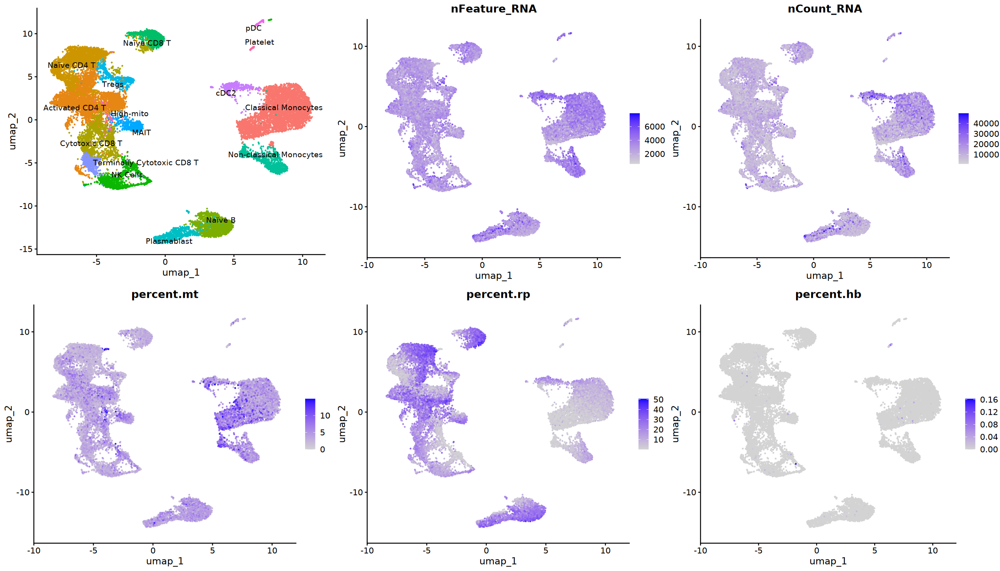

In [139]:
p1 <- DimPlot(
    sc.inte, reduction = "umap", label = TRUE, 
    label.size = 4, repel = TRUE) & NoLegend()
p2 <- FeaturePlot(
    sc.inte, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA", "percent.mt", 
                 "percent.rp", "percent.hb"))

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = c(p1, p2), ncol = 3)

In [140]:
qs2::qs_save(sc.inte, file.path(
    data_dir, "result", "s11_annotation_seurat_V5.qs2"))